# Lista 3 - Estatística Bayesiana

## Configuração do ambiente

In [151]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.integrate import quad
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.optimize import minimize
from scipy.stats import t, chi2, f, poisson, norm, uniform
import seaborn as sns 

sns.set_theme(context='notebook', style='white', palette='deep',
              rc={'figure.dpi': 500})
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'],
    'axes.unicode_minus': False,
})

## Questão 1: Distribuições amostrais e comparação de médias/variâncias

In [152]:
n1, n2 = 10, 8

mean1, mean2 = 11.33, 8.825

s1, s2 = 3.260, 1.698

nu1, nu2 = n1 - 1, n2 - 1

nu_amostras = [nu1, nu2]

labels = ['Amostra 1', 'Amostra 2']
print(f'Amostra 1: n={n1}, média={mean1}, s={s1}')
print(f'Amostra 2: n={n2}, média={mean2}, s={s2}')

Amostra 1: n=10, média=11.33, s=3.26
Amostra 2: n=8, média=8.825, s=1.698


### 1a. Intervalos de 95% para as médias e variâncias

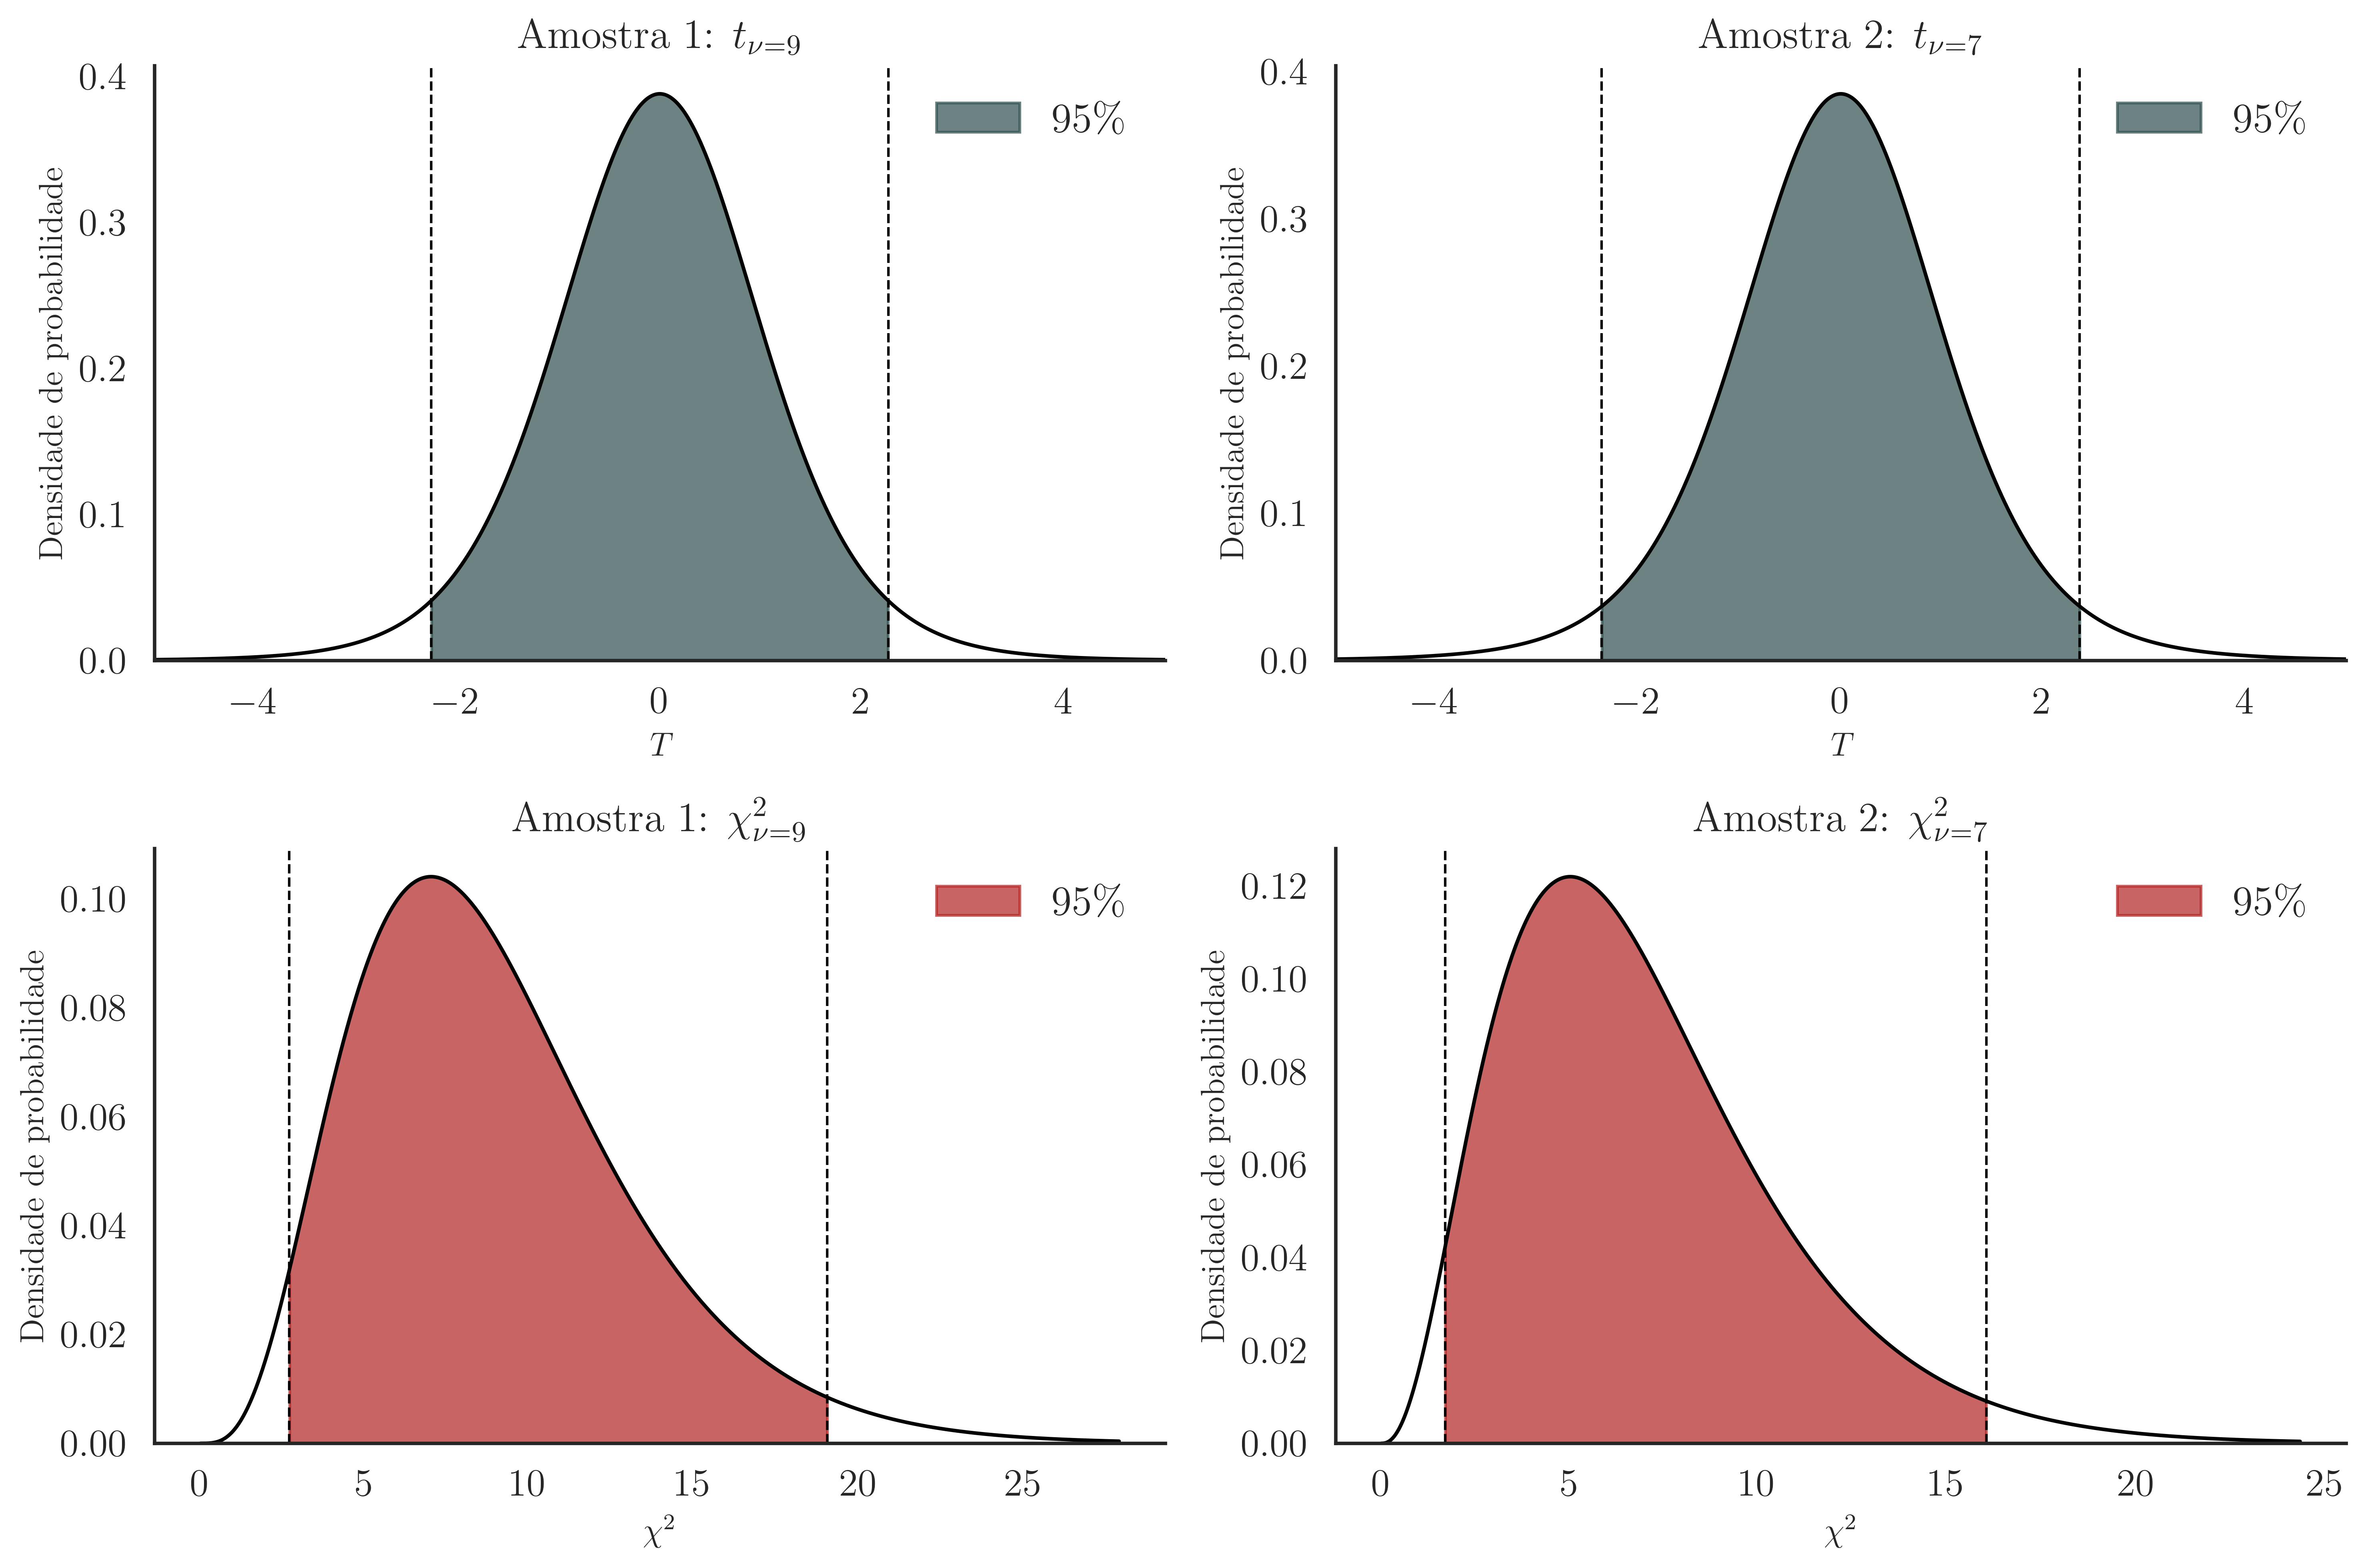

In [153]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), dpi=500)

for i, df in enumerate(nu_amostras):

    # intervalos da média
    ax = axes[0, i]

    x = np.linspace(-5, 5, 2000)
    y = t.pdf(x, df=df)

    t_inf = t.ppf(0.025, df=df)
    t_sup = t.ppf(0.975, df=df)

    ax.plot(x, y, color="black", lw=1.3)

    ax.fill_between(x, y, where=(x >= t_inf) & (x <= t_sup), color="darkslategrey", alpha=0.7, label=r"95\%")

    ax.axvline(t_inf, color="black", ls="--", lw=0.9)
    ax.axvline(t_sup, color="black", ls="--", lw=0.9)

    ax.set_title(fr"{labels[i]}: $t_{{\nu={df}}}$", fontsize=15)

    ax.set_xlabel(r"$T$")
    ax.set_ylabel("Densidade de probabilidade")
    ax.set_xlim(-5, 5)
    ax.set_ylim(bottom=0)

    ax.legend(frameon=False, fontsize=15)

    # intervalos da variância
    ax = axes[1, i]

    x = np.linspace(0, chi2.ppf(0.999, df=df), 2000)
    y = chi2.pdf(x, df=df)

    chi_inf = chi2.ppf(0.025, df=df)
    chi_sup = chi2.ppf(0.975, df=df)

    ax.plot(x, y, color="black", lw=1.3)

    ax.fill_between(x, y, where=(x >= chi_inf) & (x <= chi_sup), color="firebrick", alpha=0.7, label=r"95\%")

    ax.axvline(chi_inf, color="black", ls="--", lw=0.9)
    ax.axvline(chi_sup, color="black", ls="--", lw=0.9)

    ax.set_title(fr"{labels[i]}: $\chi^2_{{\nu={df}}}$", fontsize=15)

    ax.set_xlabel(r"$\chi^2$")
    ax.set_ylabel("Densidade de probabilidade")
    ax.set_ylim(bottom=0)

    ax.legend(frameon=False, fontsize=15)

for ax in axes.flat:
    ax.tick_params(axis="both", labelsize=14)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### 1b. Rejeição da hipótese de que as duas amostras provêm de populações com a mesma variância

In [154]:
def confidence_limit(p_value):
    return 100 * (1 - p_value)

In [155]:
F0 = (s1**2) / (s2**2)

p_F_superior = f.sf(F0, nu1, nu2)

F_inf = f.ppf(p_F_superior, nu1, nu2)

p_F_bilateral = min(1.0, 2 * p_F_superior)

print(f'F observado = {F0:.4f}')
print(f'Cauda superior = {p_F_superior:.5f}')
print(f'Valor p bilateral = {p_F_bilateral:.5f}')
print(f"Nível de confiança limite = {confidence_limit(p_F_bilateral):.2f}%")

F observado = 3.6860
Cauda superior = 0.04969
Valor p bilateral = 0.09938
Nível de confiança limite = 90.06%


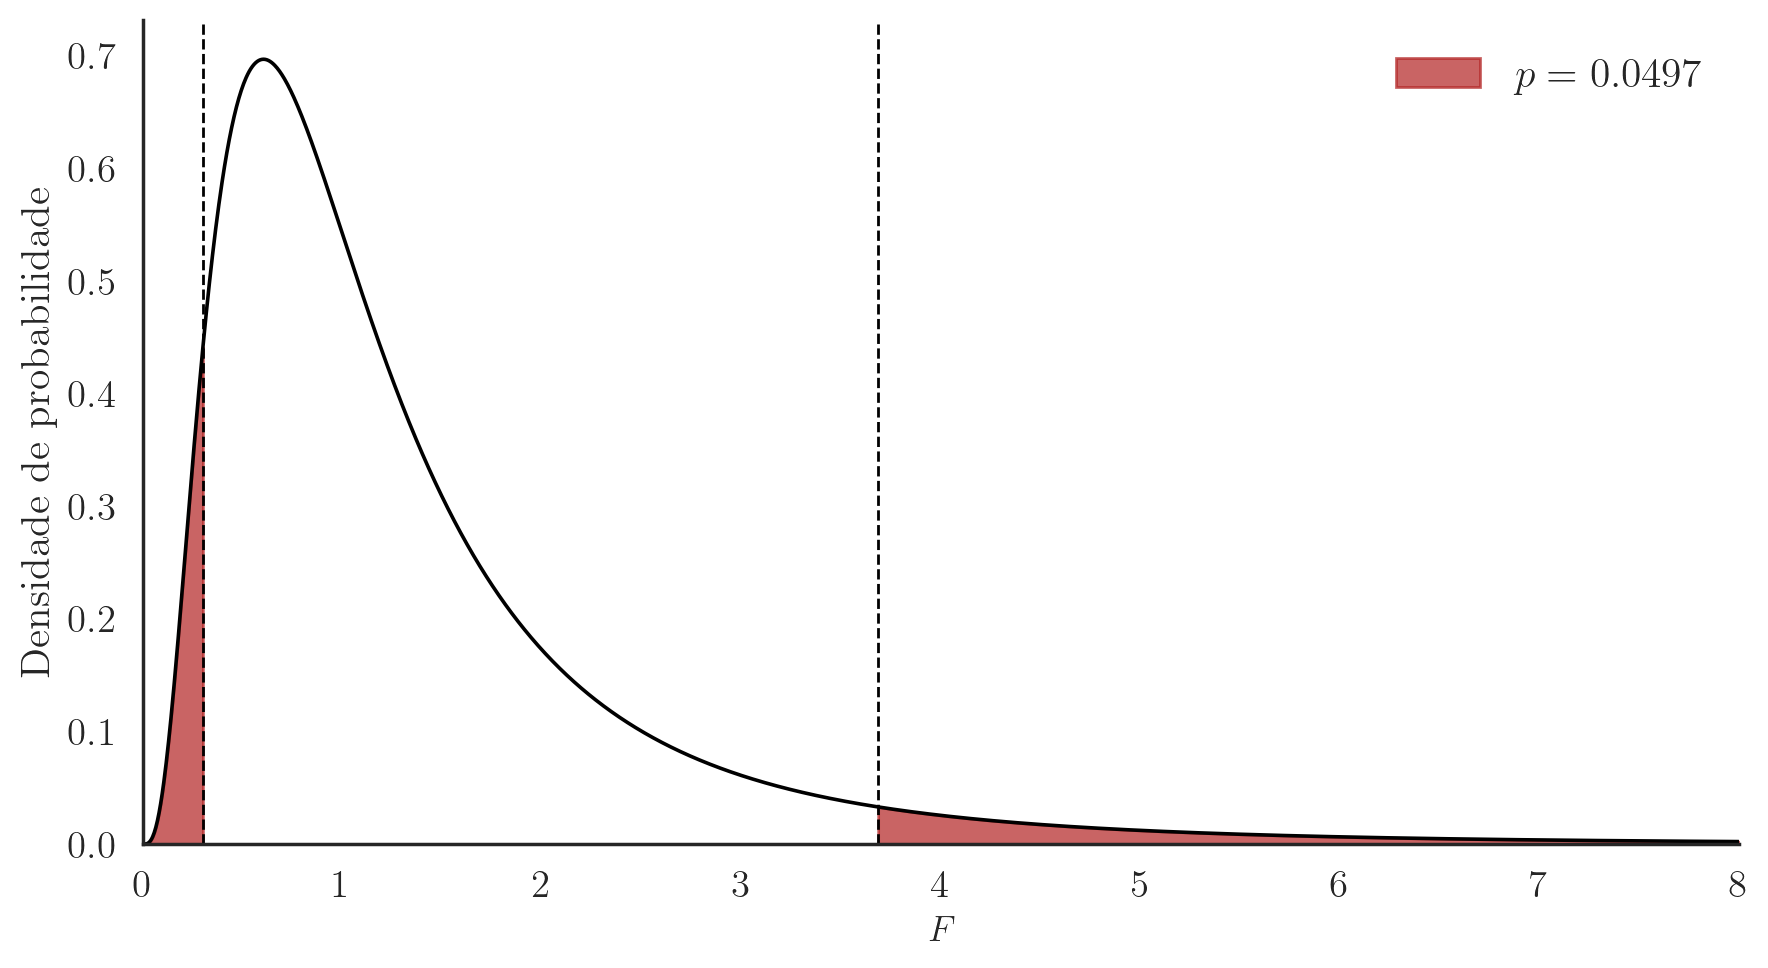

In [156]:
x = np.linspace(0.001, 8, 2000)
y = f.pdf(x, nu1, nu2)

fig, ax = plt.subplots(figsize=(9, 5), dpi=200)

ax.plot(x, y, color="black", lw=1.3)

ax.fill_between(x, y, where=(x <= F_inf), color="firebrick", alpha=0.7, label=fr"$p={p_F_superior:.4f}$")

ax.fill_between(x, y, where=(x >= F0), color="firebrick", alpha=0.7)

# Limites das duas caudas
ax.axvline(F_inf, color="black", ls="--", lw=1)
ax.axvline(F0, color="black", ls="--", lw=1)

ax.set_xlabel(r"$F$", fontsize=13)
ax.set_ylabel("Densidade de probabilidade", fontsize=15)

ax.set_xlim(0, 8)
ax.set_ylim(bottom=0)

ax.tick_params(axis="both", labelsize=14)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.show()

### 1c. Nível de confiança para rejeitar a hipótese de que as duas amostras provêm de populações com a mesma média, considerando que as variâncias populacionais são desconhecidas, porém iguais (teste bilateral)

Variância combinada S_D² = 7.23943


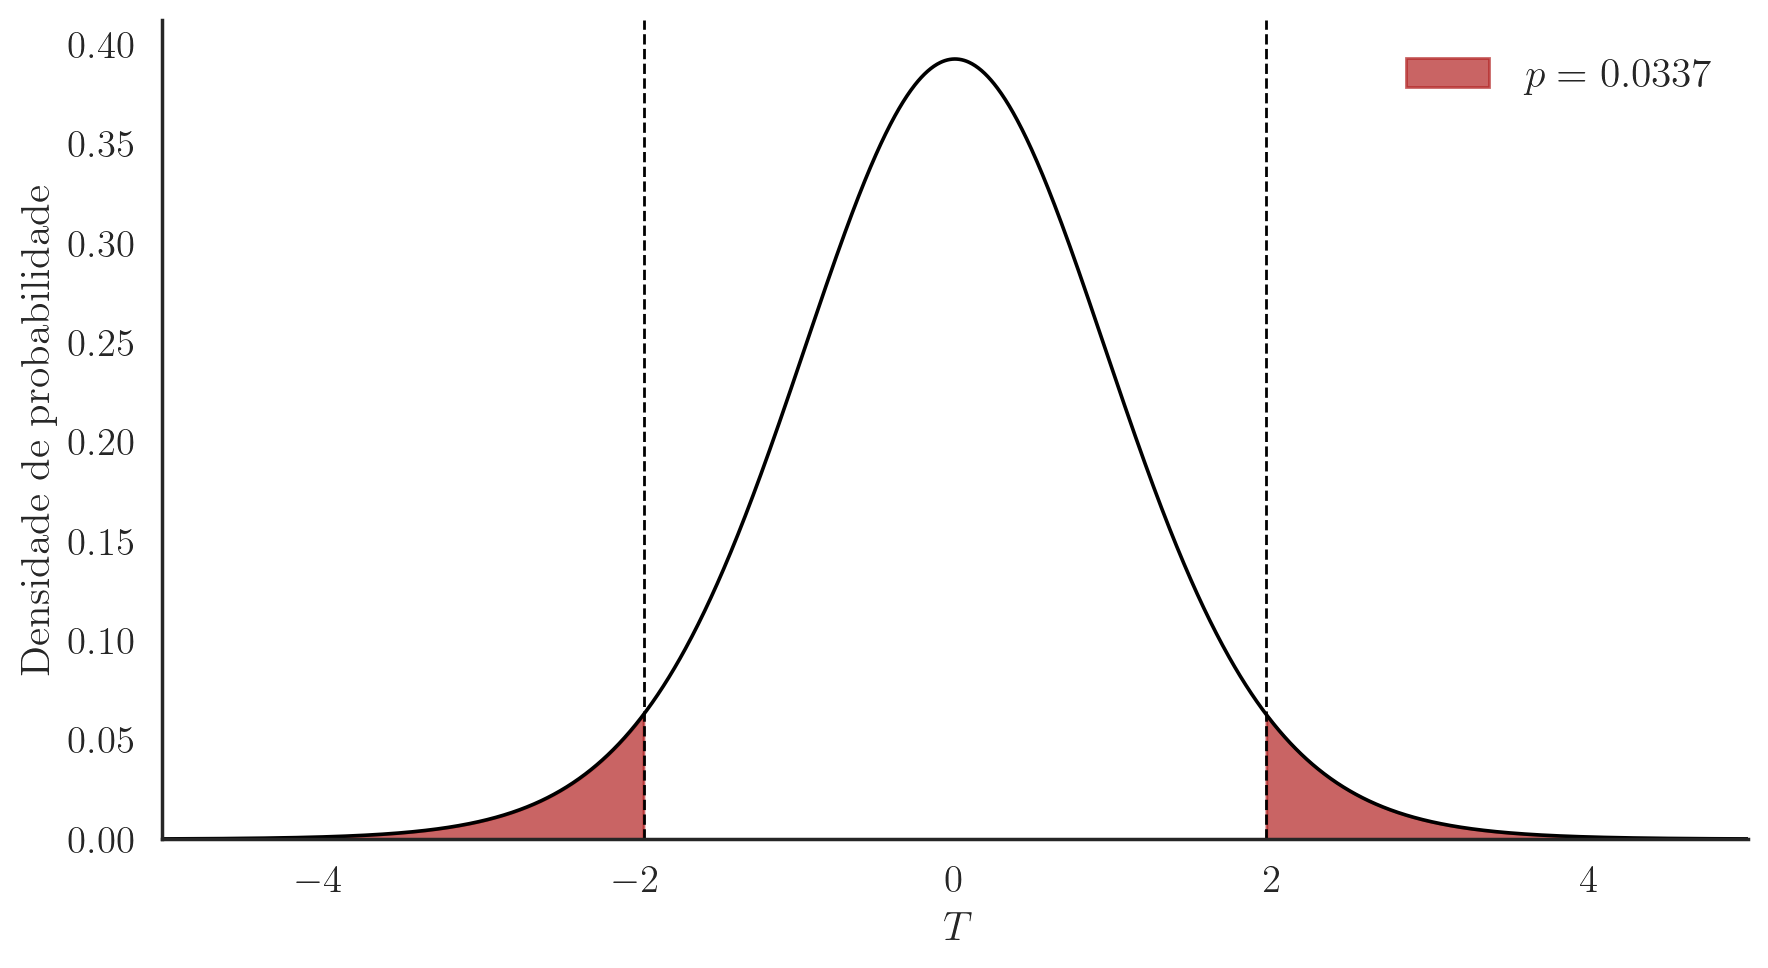

Probabilidade por cauda: 0.03365
Valor-p bilateral: 0.06730
t observado = 1.96275
Nível de confiança limite = 93.27%


In [157]:
# Graus de liberdade
nu_t = n1 + n2 - 2

S_D2 = ((n1-1)*s1**2 + (n2-1)*s2**2)/nu_t
print(f"Variância combinada S_D² = {S_D2:.5f}")

# Estatística calculada
t0 = (mean1-mean2)/(np.sqrt(S_D2)*np.sqrt(1/n1+1/n2))

# Probabilidades
p_tail = t.sf(t0, nu_t)
p_bilateral = 2 * p_tail

x = np.linspace(-5, 5, 2000)
y = t.pdf(x, nu_t)

fig, ax = plt.subplots(figsize=(9, 5), dpi=200)

ax.plot(x, y, color="black", lw=1.3)

# Cauda inferior
ax.fill_between(x, y,  where=(x <= -t0), color="firebrick", alpha=0.7, label=fr"$p={p_tail:.4f}$")

# Cauda superior
ax.fill_between(x, y, where=(x >= t0), color="firebrick", alpha=0.7)

ax.axvline(-t0, color="black", ls="--", lw=1)
ax.axvline(t0, color="black", ls="--", lw=1)

ax.set_xlabel(r"$T$", fontsize=15)
ax.set_ylabel("Densidade de probabilidade", fontsize=15)

ax.set_xlim(-5, 5)
ax.set_ylim(bottom=0)

ax.tick_params(axis="both", labelsize=14)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.show()

print(f"Probabilidade por cauda: {p_tail:.5f}")
print(f"Valor-p bilateral: {p_bilateral:.5f}")
print(f"t observado = {t0:.5f}")
print(f"Nível de confiança limite = {confidence_limit(p_bilateral):.2f}%")


### 1d. Nível de confiança para rejeitar a hipótese de que as duas amostras provêm de populações com a mesma média, considerando que as variâncias populacionais são desconhecidas e diferentes (teste bilateral)

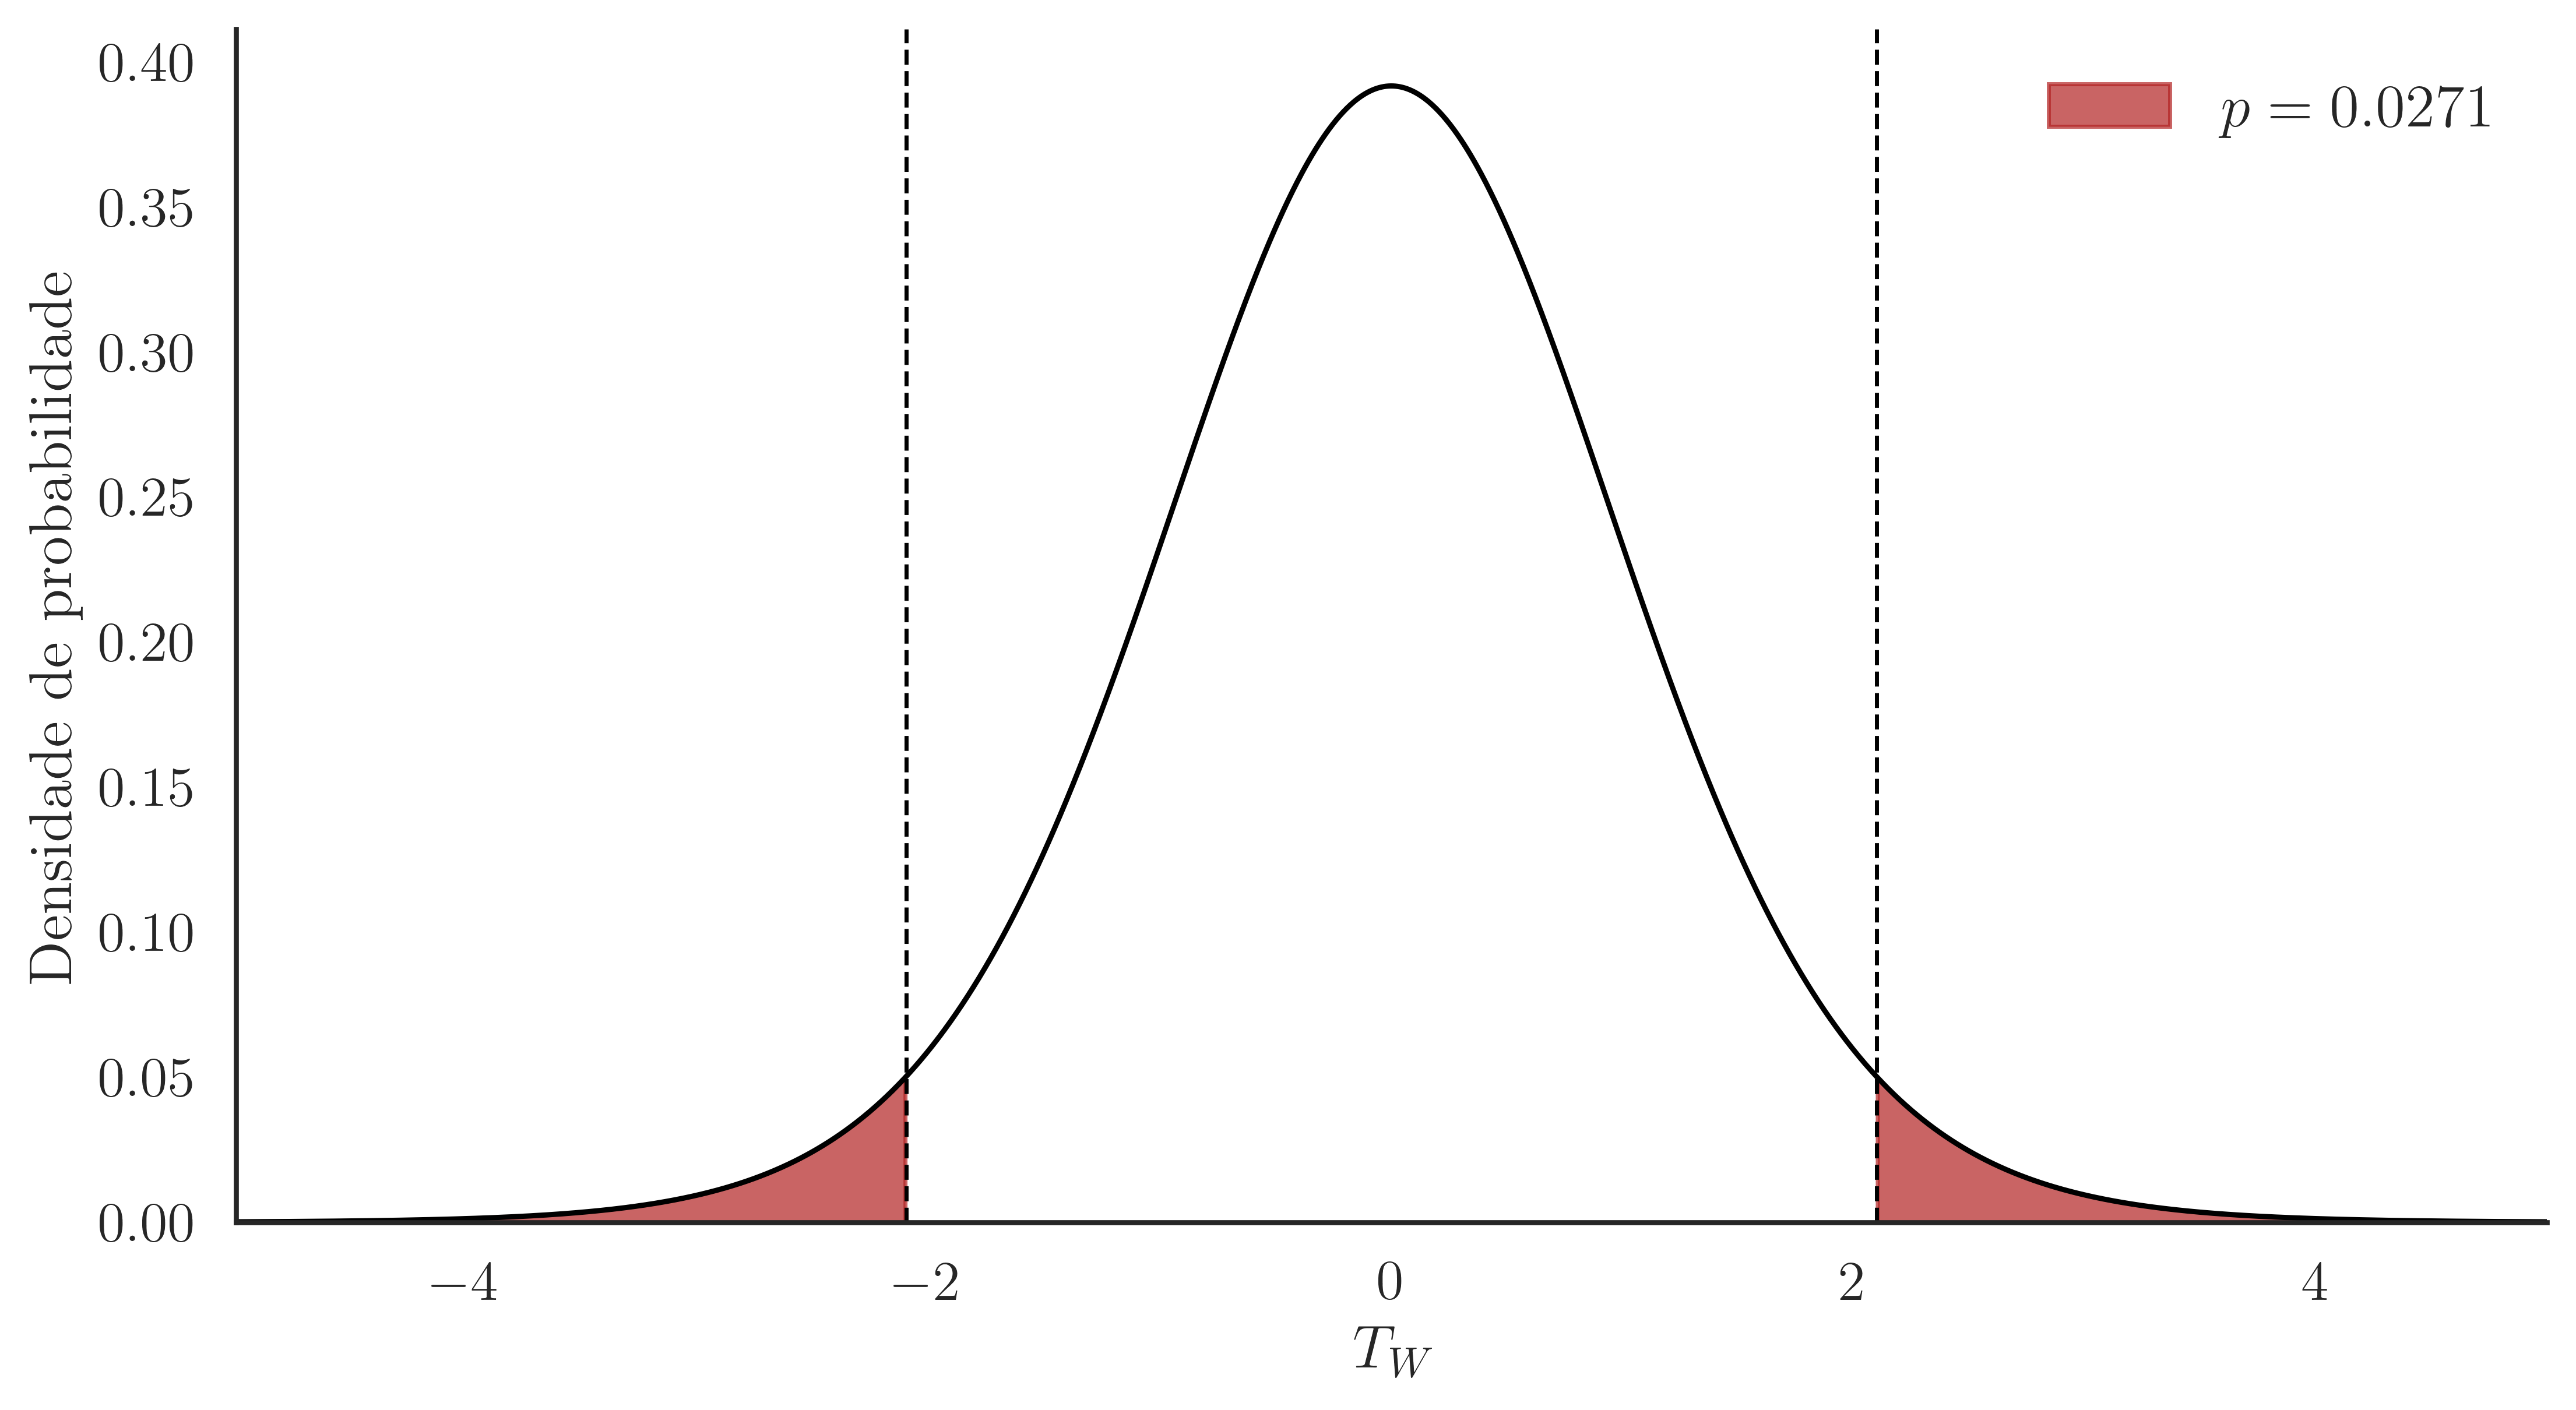

t_W = 2.0998
Graus de liberdade = 14.0602
Probabilidade por cauda = 0.02713
Valor p bilateral = 0.05427
Nível de confiança limite = 94.57%


In [158]:
# Estatística de Welch
v1 = s1**2 / n1
v2 = s2**2 / n2

t_W = (mean1 - mean2) / np.sqrt(v1 + v2)

# Graus de liberdade
nu_W = (v1 + v2)**2 / (v1**2 / (n1 - 1) + v2**2 / (n2 - 1))

# Probabilidades
p_tail = t.sf(t_W, nu_W)
p_bilateral = 2 * p_tail

x = np.linspace(-5, 5, 2000)
y = t.pdf(x, nu_W)

fig, ax = plt.subplots(figsize=(9, 5), dpi=500)

ax.plot(x, y, color="black", lw=1.3)

# Cauda inferior
ax.fill_between(x, y, where=(x <= -t_W), color="firebrick", alpha=0.7, label=fr"$p={p_tail:.4f}$")

# Cauda superior
ax.fill_between(x, y, where=(x >= t_W), color="firebrick", alpha=0.7)

ax.axvline(-t_W, color="black", ls="--", lw=1)
ax.axvline(t_W, color="black", ls="--", lw=1)

ax.set_xlabel(r"$T_W$", fontsize=15)
ax.set_ylabel("Densidade de probabilidade", fontsize=15)

ax.set_xlim(-5, 5)
ax.set_ylim(bottom=0)

ax.tick_params(axis="both", labelsize=14)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.savefig("1d.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"t_W = {t_W:.4f}")
print(f"Graus de liberdade = {nu_W:.4f}")
print(f"Probabilidade por cauda = {p_tail:.5f}")
print(f"Valor p bilateral = {p_bilateral:.5f}")
print(f"Nível de confiança limite = {confidence_limit(p_bilateral):.2f}%")

## Questão 2: Ajuste de Poisson e teste de aderência χ²


In [122]:
contagens = np.arange(13)
N_i = np.array([1, 6, 18, 17, 23, 10, 15, 4, 4, 1, 0, 0, 1])

n = np.sum(N_i)
lamb = np.sum(contagens * N_i) / n

obs = list(N_i[:8])
esperado = list(n * poisson.pmf(contagens[:8], mu=lamb))

obs.append(np.sum(N_i[8:]))
esperado.append(n * poisson.sf(7, mu=lamb))

obs = np.array(obs)
esperado = np.array(esperado)

chi_i = (obs - esperado)**2 / esperado

df_chi = pd.DataFrame({
    "Contagens": [str(i) for i in range(8)] + ["≥8"],
    "Observado (N_i)": obs,
    "Esperado (np_i)": esperado,
    "Contribuição χ²": chi_i
})

display(df_chi.round(4))

chi2_obs = np.sum(chi_i)

print(f"Lambda = {lamb:.4f}")
print(f"Chi-quadrado = {chi2_obs:.4f}")

,Contagens,Observado (N_i),Esperado (np_i),Contribuição χ²
0,0,1,1.7249,0.3046
1,1,6,7.0031,0.1437
2,2,18,14.2163,1.0070
3,3,17,19.2394,0.2607
4,4,23,19.5280,0.6173
5,5,10,15.8567,2.1632
6,6,15,10.7297,1.6995
7,7,4,6.2232,0.7942
8,≥8,6,5.4787,0.0496


Lambda = 4.0600
Chi-quadrado = 7.0399


In [123]:
nu_chi = len(obs) - 1 - 1

p_value_chi = chi2.sf(chi2_obs, df=nu_chi)

print(f'Graus de liberdade = {nu_chi}')
print(f'Valor-p = {p_value_chi:.6f}')
print('Interpretação: não rejeitamos o modelo de Poisson ao nível de 5%.' if p_value_chi >= 0.05 else 'Interpretação: rejeitamos o modelo de Poisson ao nível de 5%.')

Graus de liberdade = 7
Valor-p = 0.424737
Interpretação: não rejeitamos o modelo de Poisson ao nível de 5%.


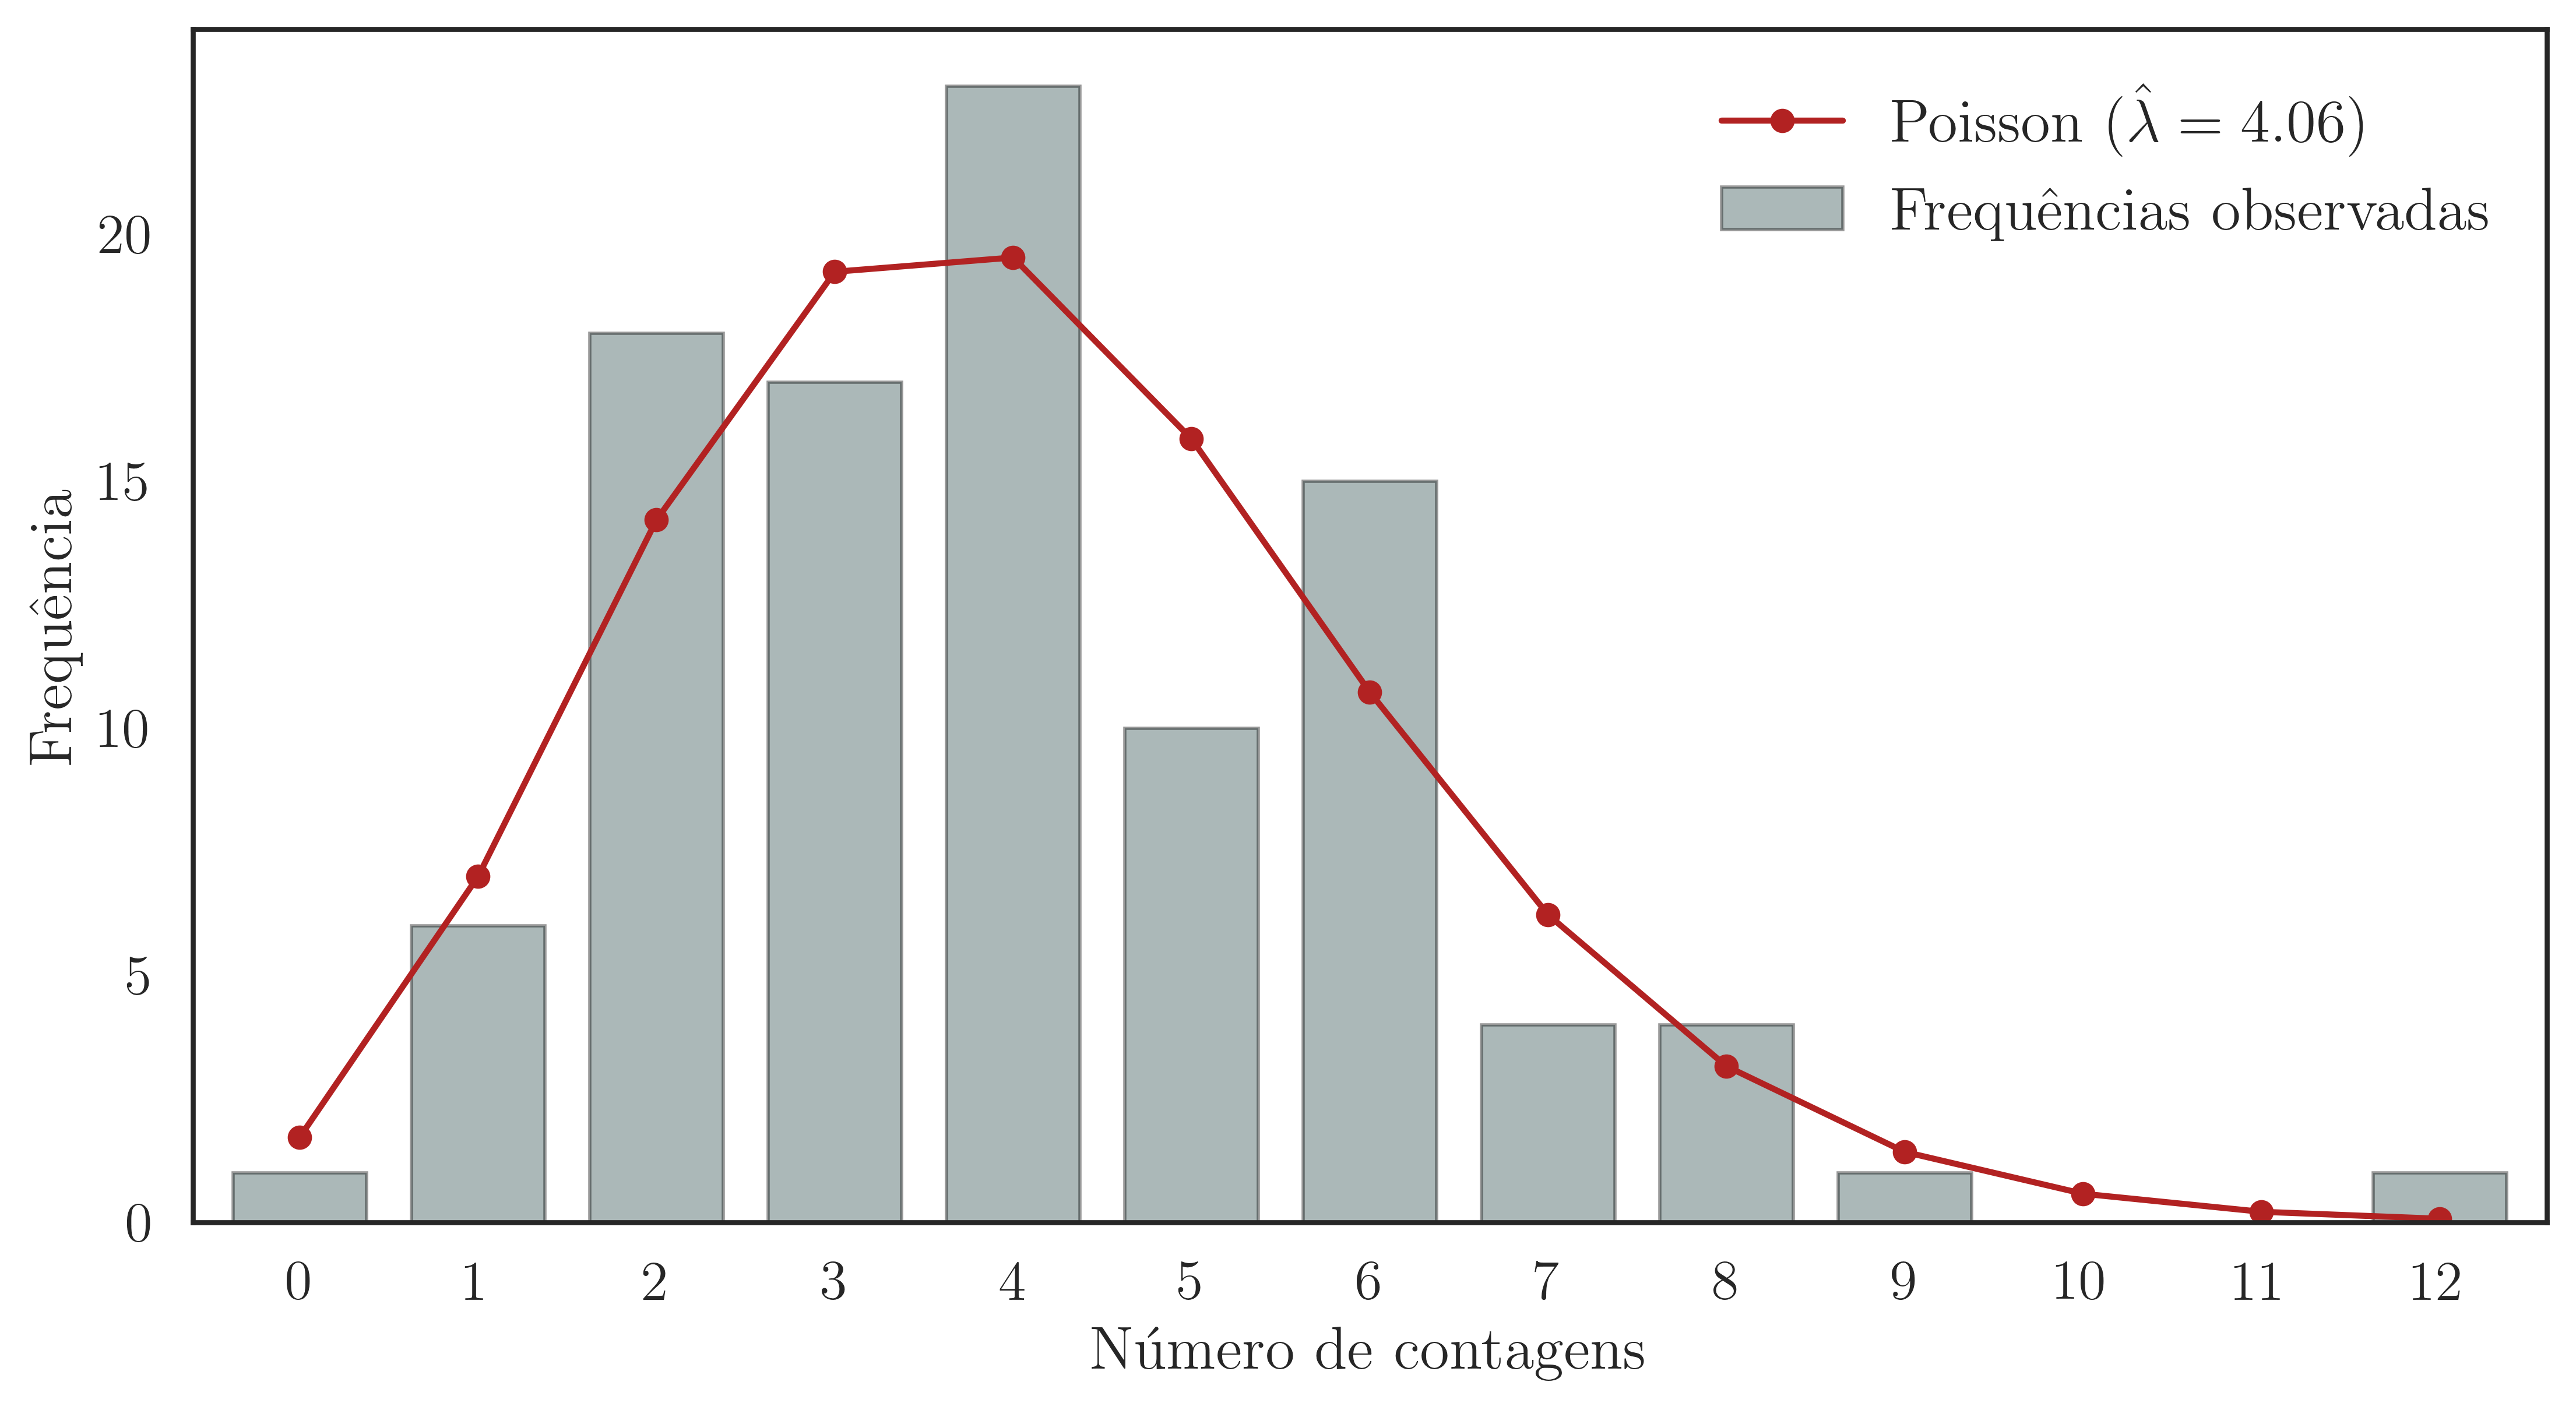

In [124]:
np_i = n * poisson.pmf(contagens, mu=lamb)

# Gráfico
fig, ax = plt.subplots(figsize=(9, 5), dpi=500)

ax.bar(contagens, N_i, width=0.75, color='darkslategrey', edgecolor='black', linewidth=0.8, alpha=0.4, label='Frequências observadas')

ax.plot(contagens, np_i, 'o-', color='firebrick', markersize=5, linewidth=1.5, label=fr'Poisson ($\hat{{\lambda}}={lamb:.2f}$)')

ax.set_xlabel('Número de contagens', fontsize=15)
ax.set_ylabel('Frequência', fontsize=15)

ax.set_xticks(contagens)
ax.set_xlim(-0.6, 12.6)
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", labelsize=14)

ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.show()

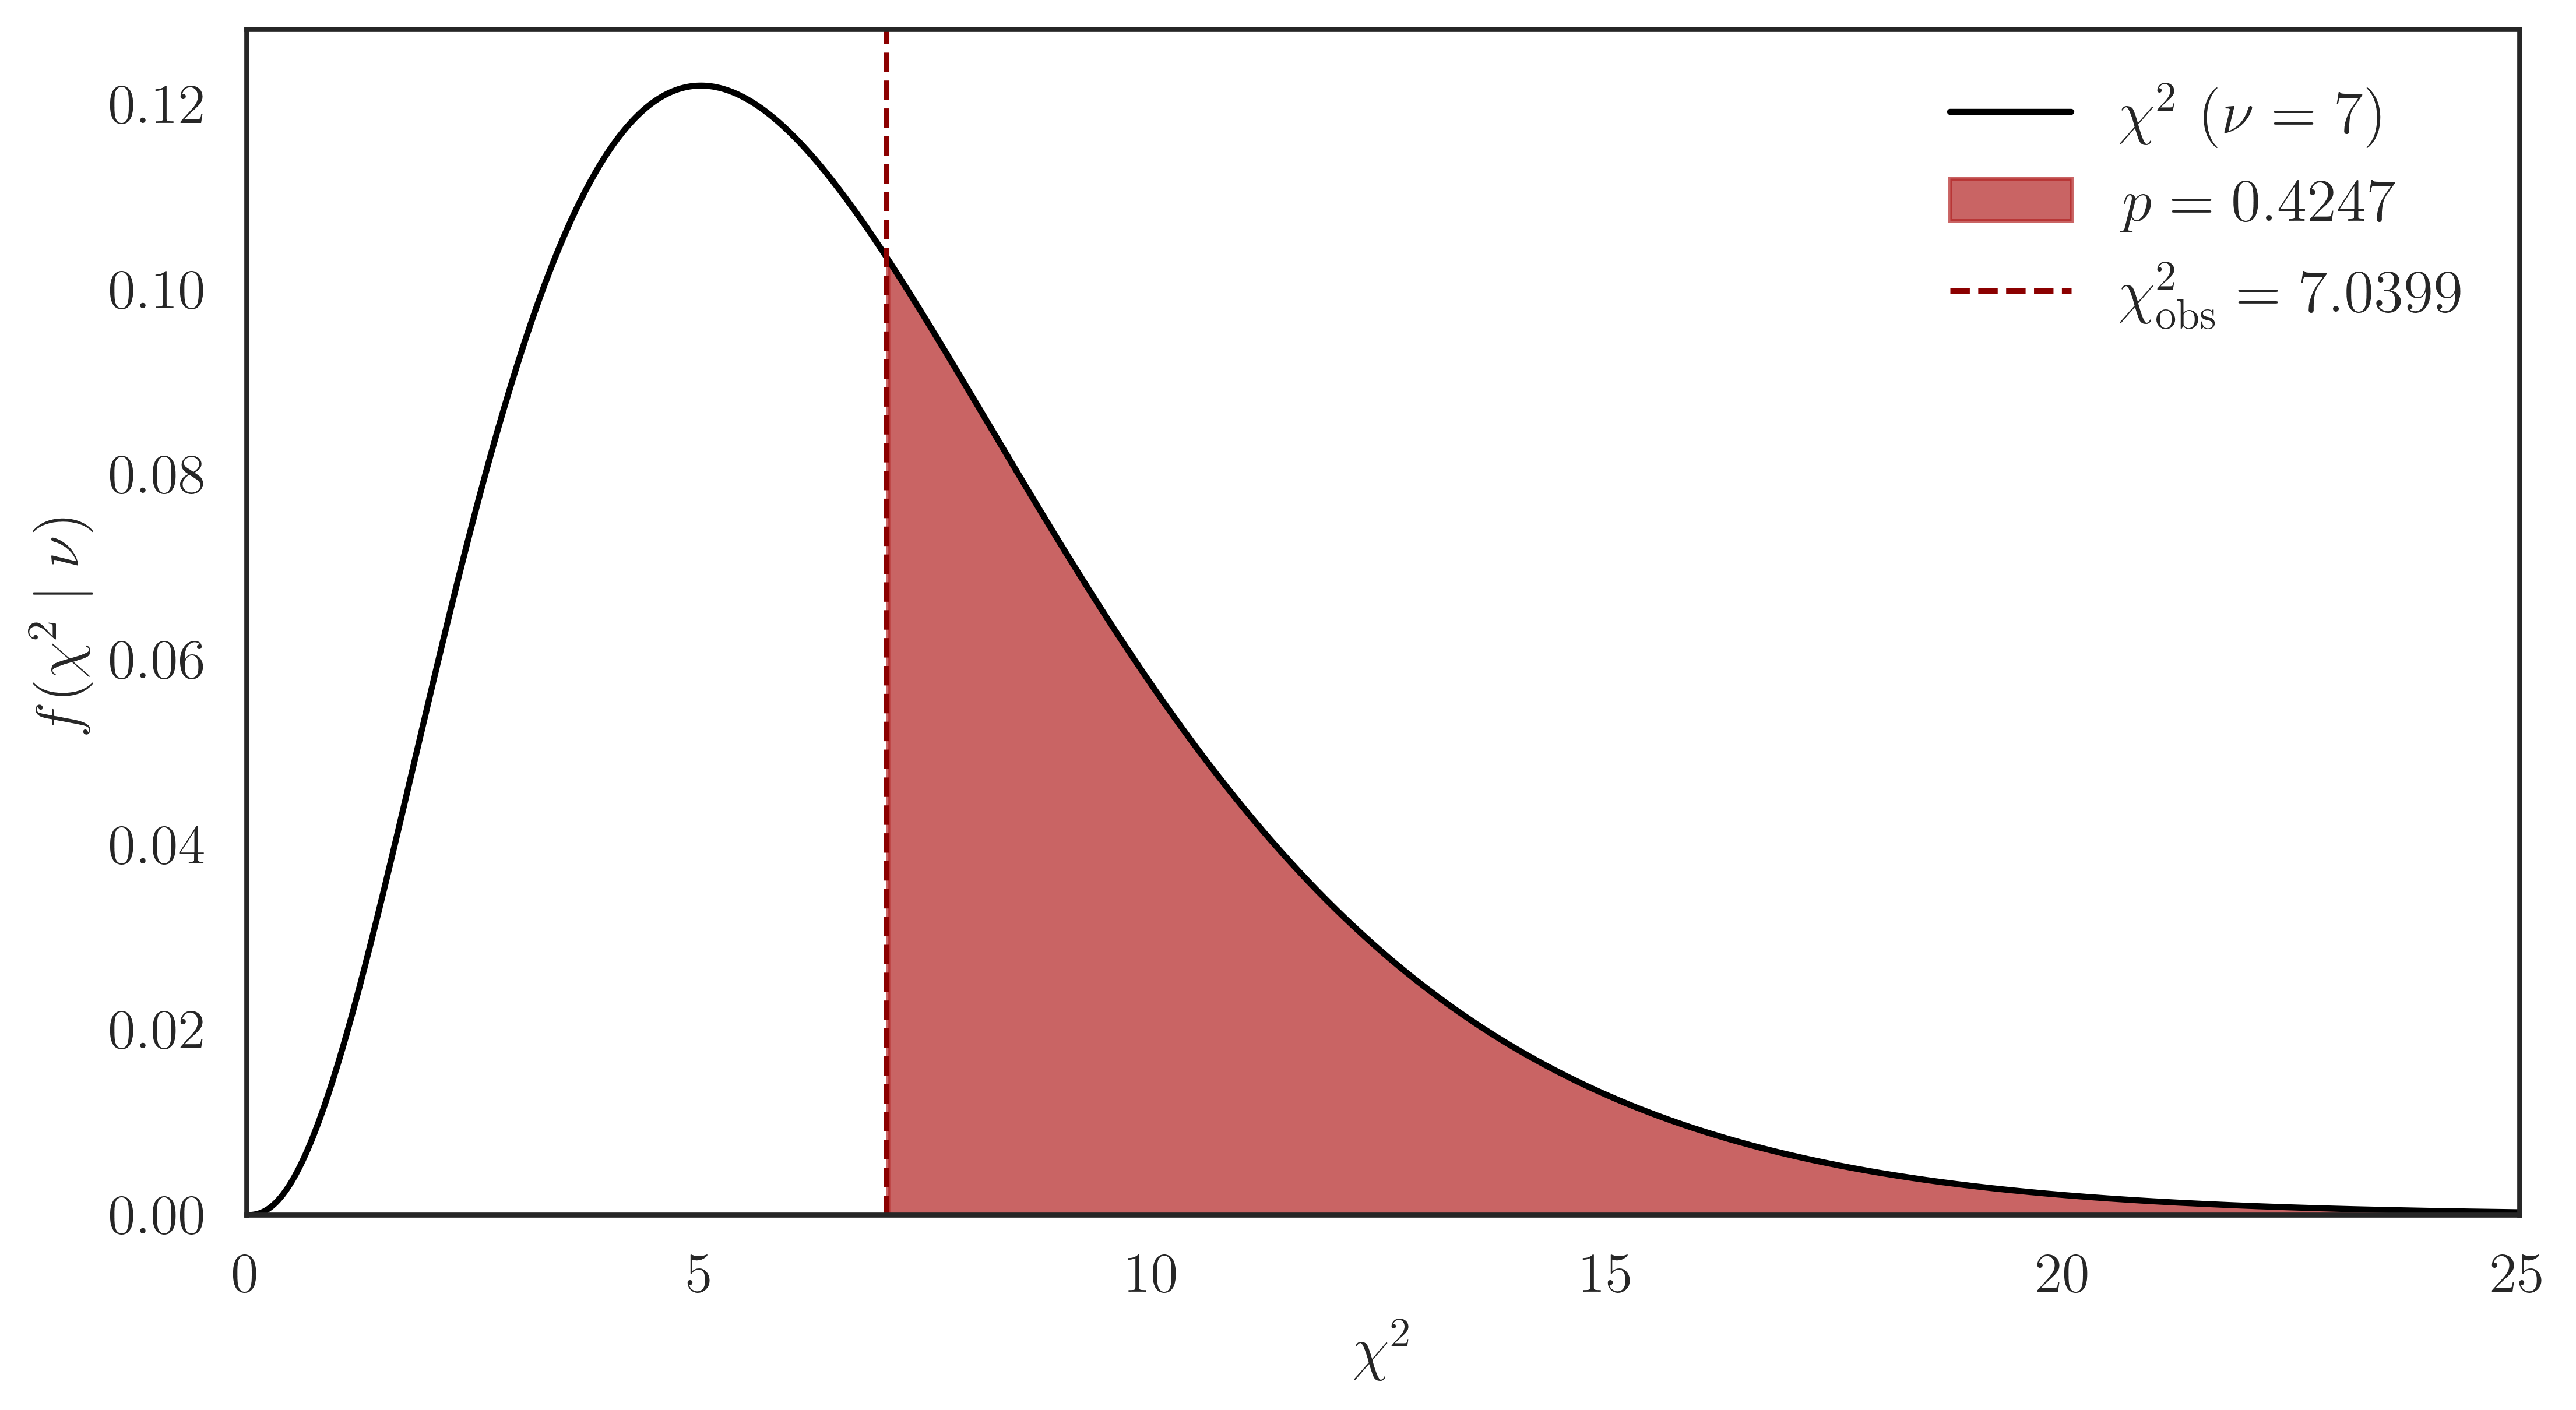

In [125]:
x = np.linspace(0, 25, 1000)
pdf = chi2.pdf(x, df=nu_chi)

fig, ax = plt.subplots(figsize=(9, 5), dpi=500)

ax.plot(x, pdf, color='black', lw=1.5, label=fr'$\chi^2$ ($\nu={nu_chi}$)')

ax.fill_between(x, pdf, where=(x >= chi2_obs), color='firebrick', alpha=0.7,label=fr'$p={p_value_chi:.4f}$')

ax.axvline(chi2_obs, color='darkred', ls='--', lw=1.3, label=fr'$\chi^2_{{\mathrm{{obs}}}}={chi2_obs:.4f}$')

ax.set_xlabel(r'$\chi^2$', fontsize=15)
ax.set_ylabel(r'$f(\chi^2\mid\nu)$', fontsize=15)

ax.set_xlim(0, 25)
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", labelsize=14)

ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.show()

## Questão 3: Média de medidas com incertezas gaussianas distintas

### 3(a) — Média ponderada e incerteza

In [126]:
V = np.array([4.36, 4.00, 4.87, 5.64, 6.14, 5.92, 3.93, 6.58, 3.78, 5.84])

sigma = np.array([2.24, 1.94, 1.39, 2.55, 1.69, 1.38, 1.00, 1.60, 1.00, 1.00])

w = 1 / sigma**2

mu_pond = np.sum(w * V) / np.sum(w)

sigma_mean = np.sqrt(1 / np.sum(w))

print(f'Média ponderada = {mu_pond:.6f}')
print(f'Incerteza da média = {sigma_mean:.6f}')

def likelihood(mu):
    soma = 0
    for i in range(len(V)):
        soma += (V[i] - mu)**2 / (2 * sigma[i]**2)
    return np.exp(-soma)

Média ponderada = 4.942118
Incerteza da média = 0.430243


### 3b. Posteriori com priori uniforme em [3, 7]

In [127]:
mu_min_b, mu_max_b = 3.0, 7.0
evidencia_b, erro_b = quad(likelihood, mu_min_b, mu_max_b)

def posterior_b(mu):
    if mu < mu_min_b or mu > mu_max_b:
        return 0.0
    return likelihood(mu) / evidencia_b

integral_b, _ = quad(posterior_b, mu_min_b, mu_max_b)
print(f'Evidência = {evidencia_b:.8f}')
print(f'Integral da posteriori (b) = {integral_b:.8f}')

mu_grid_b = np.linspace(3, 7, 1000)
p_grid_b = []
for mu in mu_grid_b:
    p_grid_b.append(posterior_b(mu))

Evidência = 0.06510717
Integral da posteriori (b) = 1.00000000


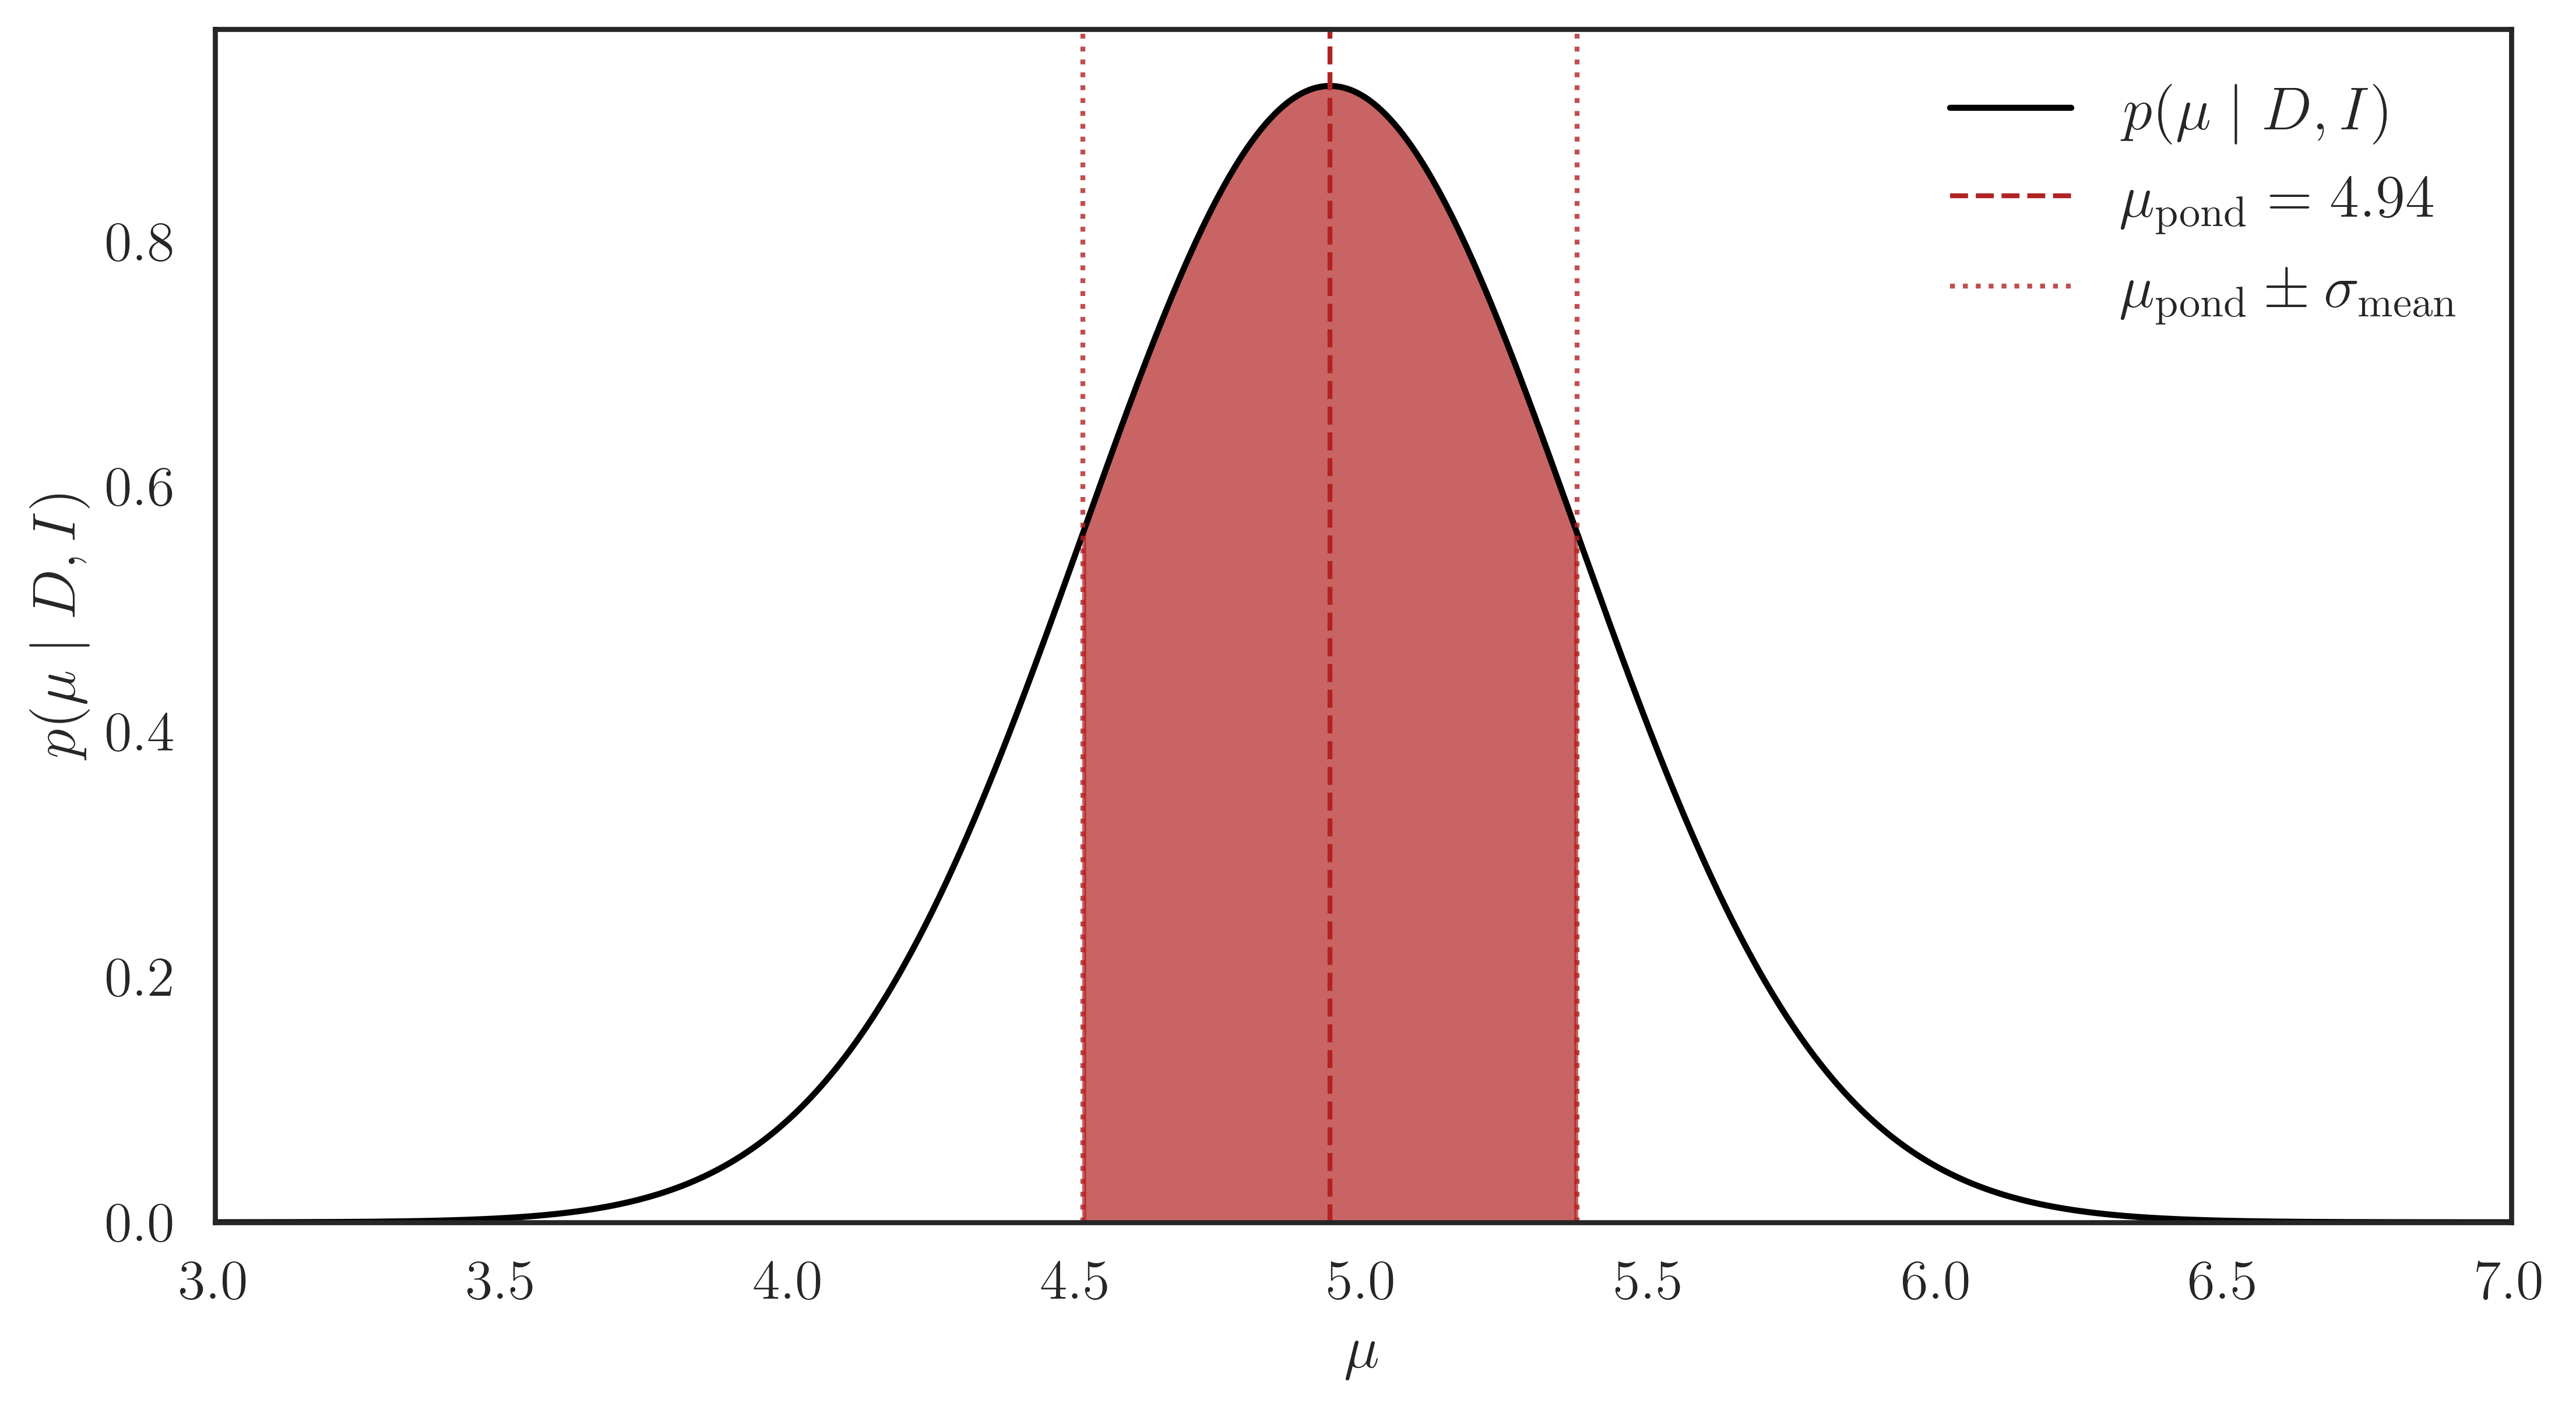

In [128]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=500)

ax.plot(mu_grid_b, p_grid_b, color='black', lw=1.5, label=r'$p(\mu\mid D,I)$')

ax.axvline(mu_pond, ls='--', color='firebrick', lw=1.2, label=fr'$\mu_{{\mathrm{{pond}}}}={mu_pond:.2f}$')

ax.axvline(mu_pond - sigma_mean, ls=':', color='firebrick', lw=1.2, alpha=0.8, label=r'$\mu_{\mathrm{pond}}\pm\sigma_{\mathrm{mean}}$')

ax.axvline(mu_pond + sigma_mean, ls=':', color='firebrick', alpha=0.8, lw=1.2)

ax.fill_between(mu_grid_b, p_grid_b, where=(mu_grid_b >= mu_pond - sigma_mean) & (mu_grid_b <= mu_pond + sigma_mean), color='firebrick', alpha=0.7)

ax.set_xlabel(r'$\mu$', fontsize=15)
ax.set_ylabel(r'$p(\mu\mid D,I)$', fontsize=15)

ax.set_xlim(3, 7)
ax.set_ylim(bottom=0)
ax.tick_params(axis='both', labelsize=14)

ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.savefig('3b.png', bbox_inches='tight')
plt.show()

### 3c. Região de confiança de 68,3%


In [129]:
alpha_c = 1 - 0.683

mu_grid_c = np.linspace(mu_min_b, mu_max_b, 10000)

prob_c = []
for mu in mu_grid_c:
    integral, _ = quad(posterior_b, mu_min_b, mu)
    prob_c.append(integral)

prob_c = np.array(prob_c)

L1_c = mu_grid_c[np.argmin(abs(prob_c - alpha_c/2))]

L2_c = mu_grid_c[np.argmin(abs(prob_c - (1 - alpha_c/2)))]

area_c, _ = quad(posterior_b, L1_c, L2_c)

print(f'Região de 68,3%: [{L1_c:.6f}, {L2_c:.6f}]')
print(f'Probabilidade = {area_c:.6f}')
print(f'Média ± incerteza: [{mu_pond-sigma_mean:.6f}, {mu_pond+sigma_mean:.6f}]')

Região de 68,3%: [4.511751, 5.372637]
Probabilidade = 0.682917
Média ± incerteza: [4.511875, 5.372362]


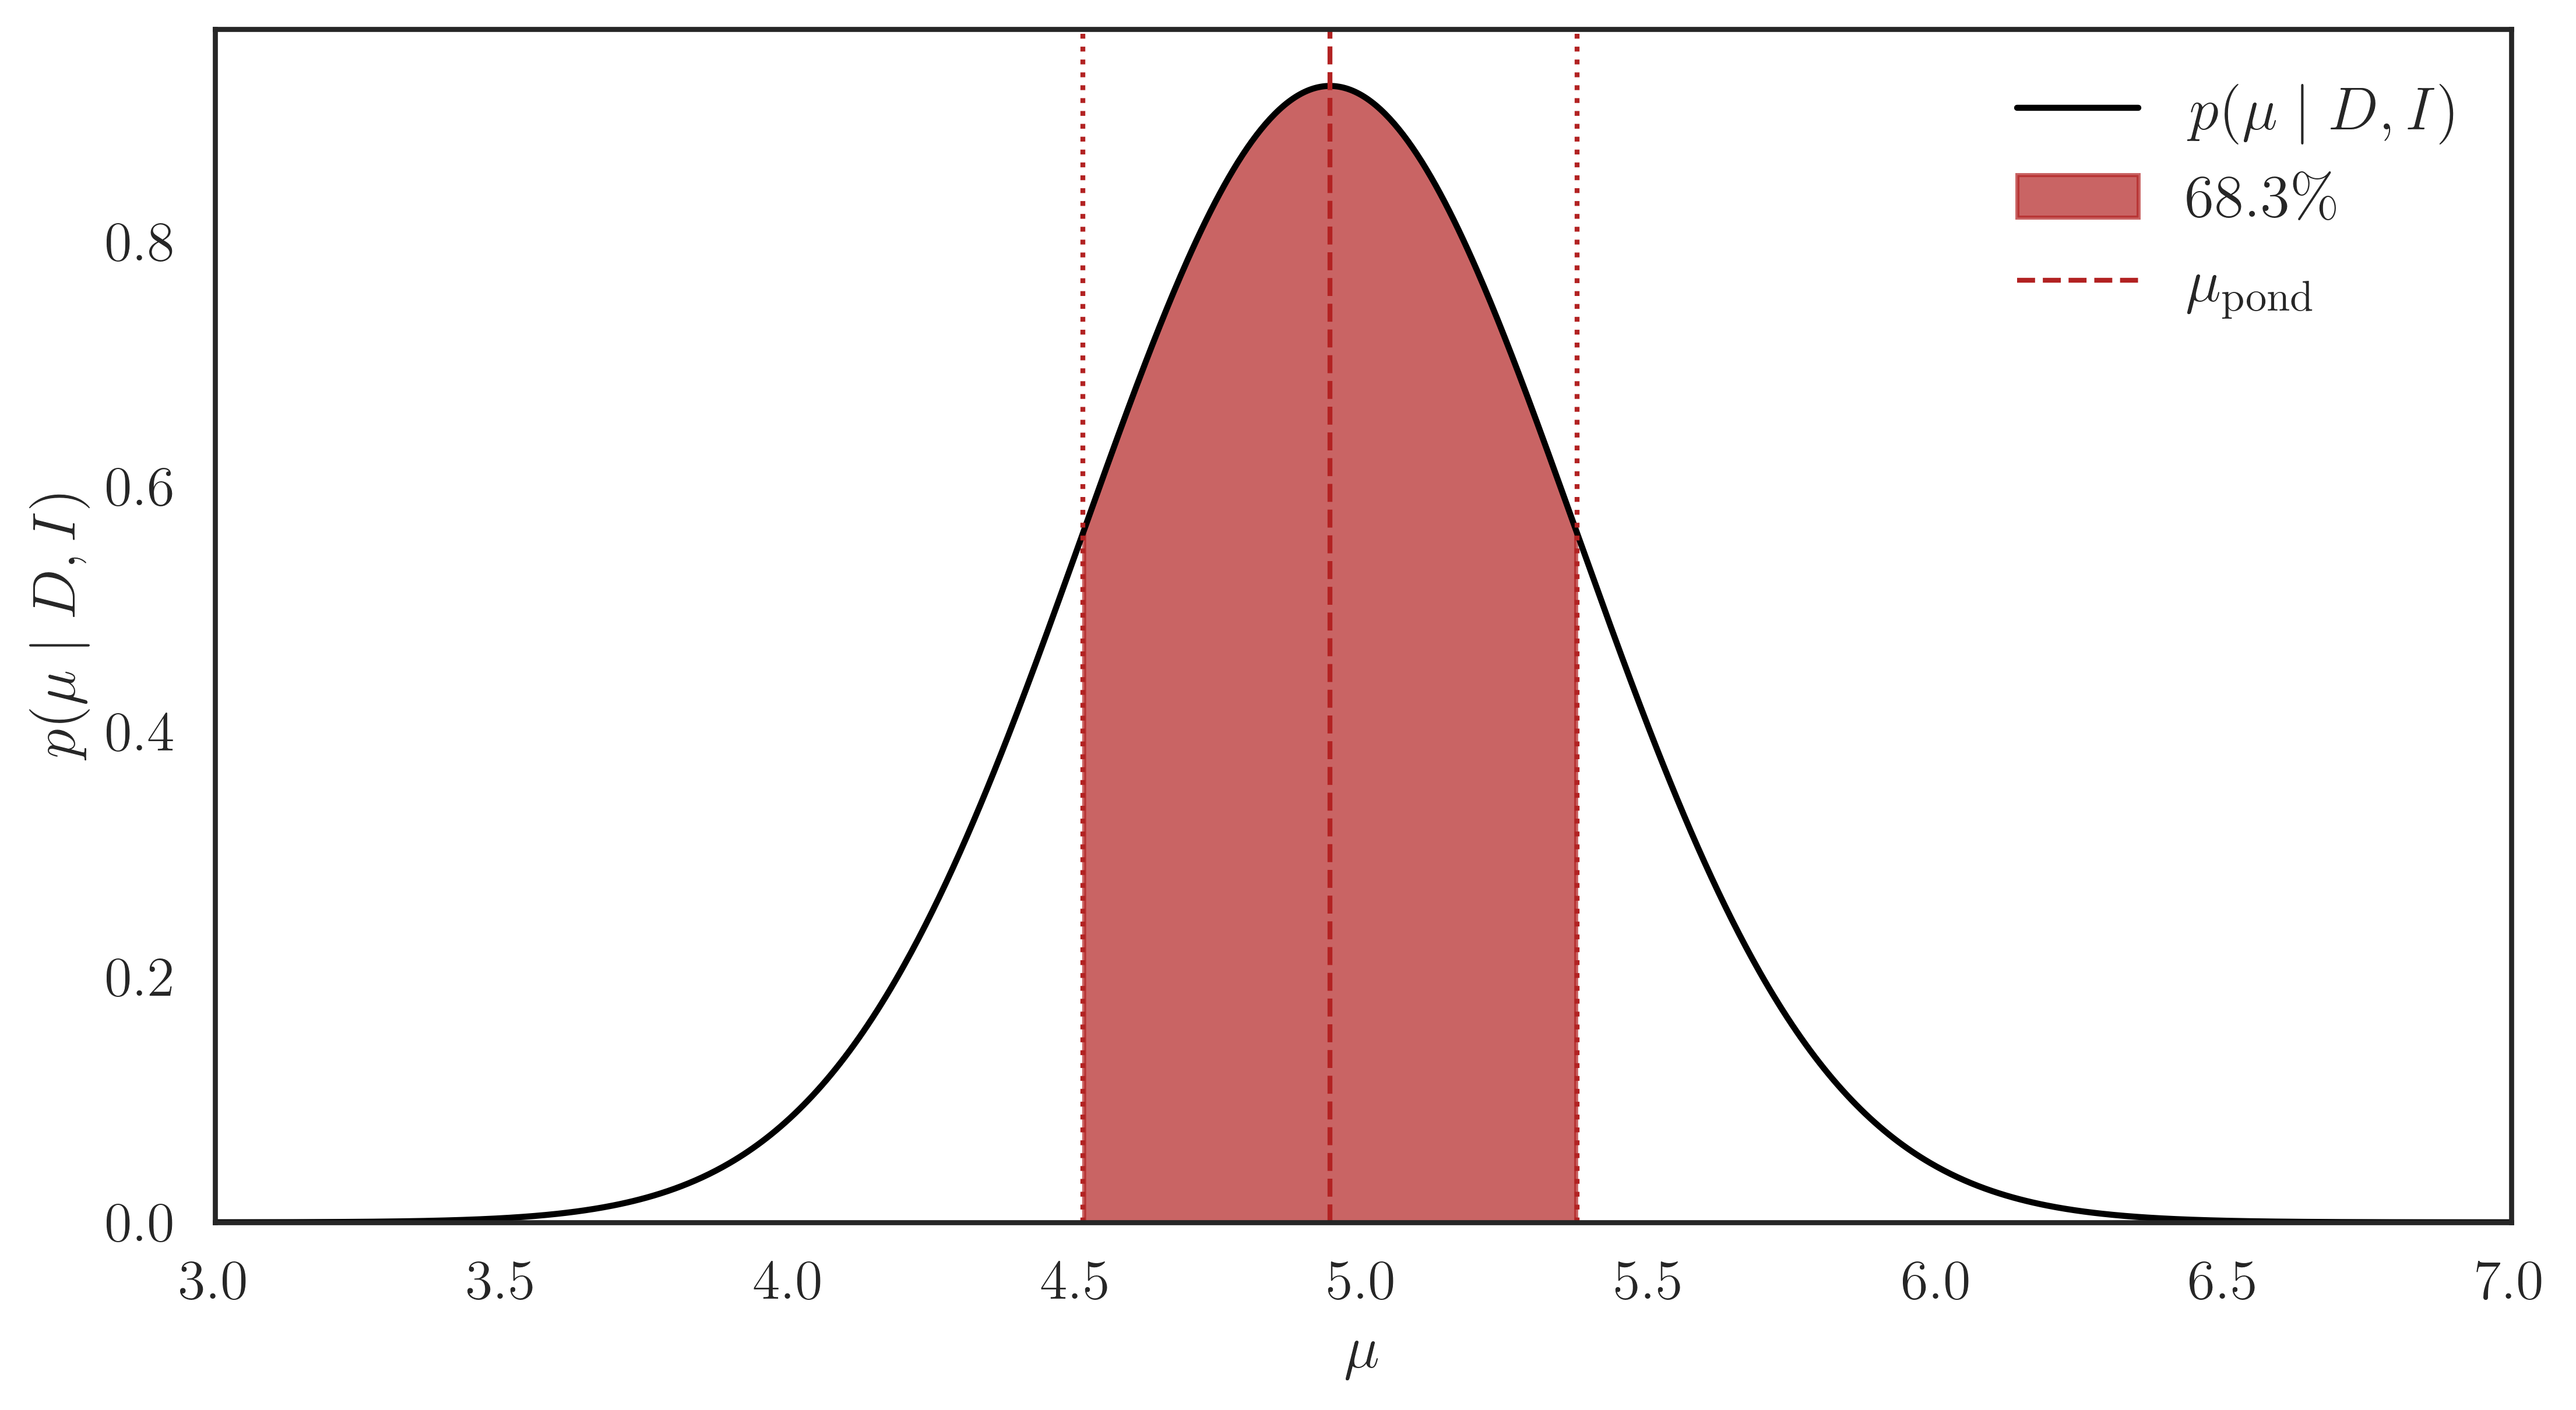

In [130]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=500)

ax.plot(mu_grid_b, p_grid_b, color='black', lw=1.5, label=r'$p(\mu\mid D,I)$')

ax.fill_between(mu_grid_b, p_grid_b, where=(mu_grid_b >= L1_c) & (mu_grid_b <= L2_c), color='firebrick', alpha=0.7, label=r'$68.3\%$')

ax.axvline(mu_pond, color='firebrick', ls='--', lw=1.2, label=r'$\mu_{\mathrm{pond}}$')

# Limites da região de credibilidade
ax.axvline(L1_c, color='firebrick', ls=':', lw=1.2)
ax.axvline(L2_c, color='firebrick', ls=':', lw=1.2)

ax.set_xlabel(r'$\mu$', fontsize=15)
ax.set_ylabel(r'$p(\mu\mid D,I)$', fontsize=15)

ax.set_xlim(3, 7)
ax.set_ylim(bottom=0)
ax.tick_params(axis='both', labelsize=14)

ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.savefig('3c.png', bbox_inches='tight')
plt.show()

### 3d. Posteriori com priori uniforme em [4.6, 5.4]

In [131]:
mu_min_d, mu_max_d = 4.6, 5.4

evidencia_d, erro_d = quad(likelihood, mu_min_d, mu_max_d)

def posterior_d(mu):
    if mu < mu_min_d or mu > mu_max_d:
        return 0.0
    return likelihood(mu) / evidencia_d

integral_d, _ = quad(posterior_d, mu_min_d, mu_max_d)

print(f'Evidência = {evidencia_d:.8f}')
print(f'Integral da posteriori (d) = {integral_d:.8f}')

mu_grid_d = np.linspace(3, 7, 1000)

p_grid_d = []
for mu in mu_grid_d:
    p_grid_d.append(posterior_d(mu))

Evidência = 0.04187278
Integral da posteriori (d) = 1.00000000


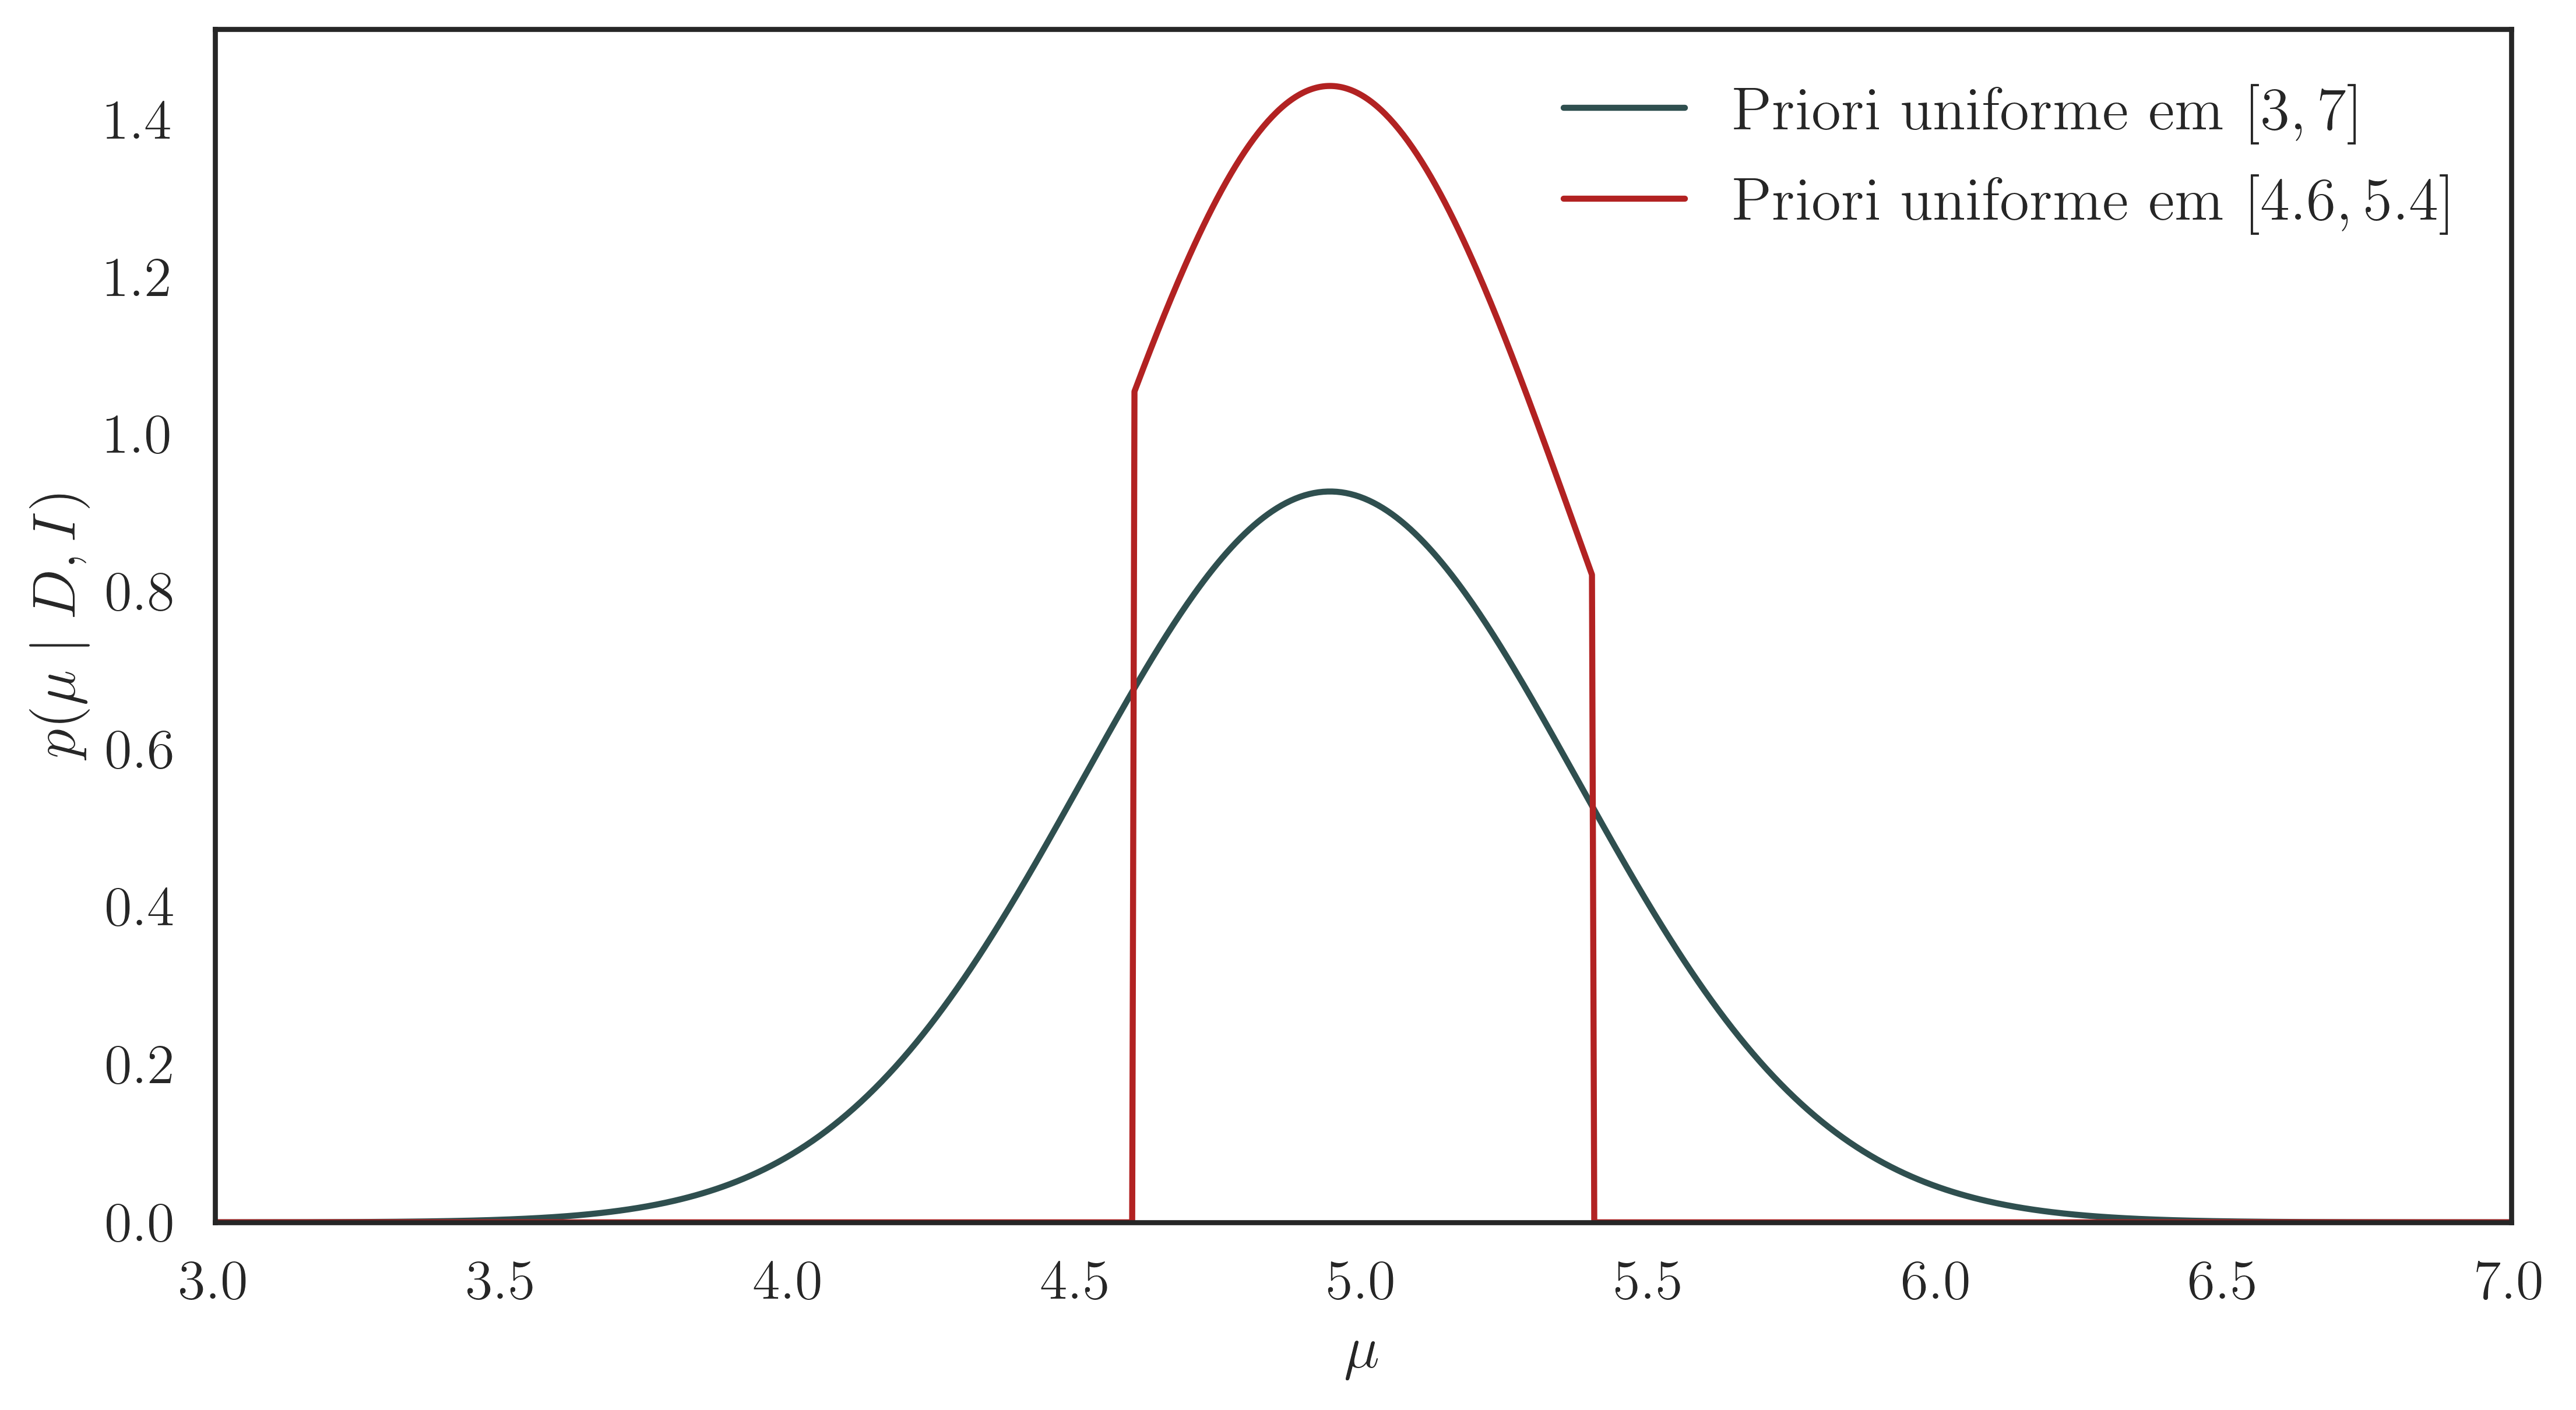

In [132]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=500)

ax.plot(mu_grid_b, p_grid_b, color='darkslategrey', lw=1.5, label=r'Priori uniforme em $[3,7]$')

ax.plot( mu_grid_d, p_grid_d, color='firebrick', lw=1.5, label=r'Priori  uniforme em $[4.6,5.4]$')

ax.set_xlabel(r'$\mu$', fontsize=15)
ax.set_ylabel(r'$p(\mu\mid D,I)$', fontsize=15)

ax.set_xlim(3, 7)
ax.set_ylim(bottom=0)

ax.tick_params(axis='both', labelsize=14)
ax.legend(frameon=False, fontsize=15)

plt.tight_layout()
plt.savefig('3d.png', bbox_inches='tight')
plt.show()

### 3e. Região de confiança de 68%

In [133]:
alpha_e = 1 - 0.68

mu_grid_e = np.linspace(mu_min_d, mu_max_d, 10000)

prob_e = []
for mu in mu_grid_e:
    integral, _ = quad(posterior_d, mu_min_d, mu)
    prob_e.append(integral)

prob_e = np.array(prob_e)

L1_e = mu_grid_e[np.argmin(abs(prob_e - alpha_e/2))]

L2_e = mu_grid_e[np.argmin(abs(prob_e - (1 - alpha_e/2)))]

area_e, _ = quad(posterior_d, L1_e, L2_e)

print(f'(c), 68,3%: [{L1_c:.6f}, {L2_c:.6f}]')
print(f'(e), 68,0%: [{L1_e:.6f}, {L2_e:.6f}]')
print(f'Probabilidade (e) = {area_e:.6f}')
print(f'Largura em (c) = {L2_c-L1_c:.6f}')
print(f'Largura em (e) = {L2_e-L1_e:.6f}')

(c), 68,3%: [4.511751, 5.372637]
(e), 68,0%: [4.736254, 5.237024]
Probabilidade (e) = 0.679973
Largura em (c) = 0.860886
Largura em (e) = 0.500770


## Questão 4 — Posteriori tridimensional e contornos HPD

### 4a. Cortes em $w=0$, $y=0$, $x=0$

In [134]:
def likelihood_4(x, y, w, mu_x=5, sigma_x=3, sigma_y=6):
    return np.exp((-1/2)*((x-mu_x)/sigma_x)**2)*np.exp((-1/2)*((y + 0.5*y**2 + 0.3*x**2 + w)/sigma_y)**2)*(2*w**2 + 3)

def prior_4(x, y, w):
    return (uniform.pdf(x, loc=-13, scale=26) * uniform.pdf(y, loc=-13,  scale=26) * norm.pdf(w, loc=0, scale=4))

def posterior_4(x, y, w):
    return likelihood_4(x, y, w) * prior_4(x, y, w)

def normalization(P, u, v):
    total = np.trapezoid(np.trapezoid(P, u, axis=1), v, axis=0)
    return P/total

In [135]:
N4 = 200

x4 = np.linspace(-13, 13, N4)
y4 = np.linspace(-13, 13, N4)
w4 = np.linspace(-20, 20, N4)

X_xy, Y_xy = np.meshgrid(x4, y4)
X_xw, W_xw = np.meshgrid(x4, w4)
Y_yw, W_yw = np.meshgrid(y4, w4)

P_xy = posterior_4(X_xy, Y_xy, 0)
P_xw = posterior_4(X_xw, 0, W_xw)
P_yw = posterior_4(0, Y_yw, W_yw)

In [136]:
P_xy_a = normalization(posterior_4(X_xy, Y_xy, 0), x4, y4)
P_xw_a = normalization(posterior_4(X_xw, 0, W_xw), x4, w4)
P_yw_a = normalization(posterior_4(0, Y_yw, W_yw), y4, w4)

In [137]:
def credible_levels(P, x, y):

    probabilidades = [0.683, 0.954, 0.9973]

    dx = x[1] - x[0]
    dy = y[1] - y[0]

    valores = np.sort(P.flatten())[::-1]
    acumulada = np.cumsum(valores) * dx * dy

    niveis = []

    for p in probabilidades:
        indice = np.searchsorted(acumulada, p)
        niveis.append(valores[min(indice, len(valores) - 1)])

    return sorted(niveis)

In [138]:
levels_xy_a = credible_levels(P_xy_a, x4, y4)
levels_xw_a = credible_levels(P_xw_a, x4, w4)
levels_yw_a = credible_levels(P_yw_a, y4, w4)

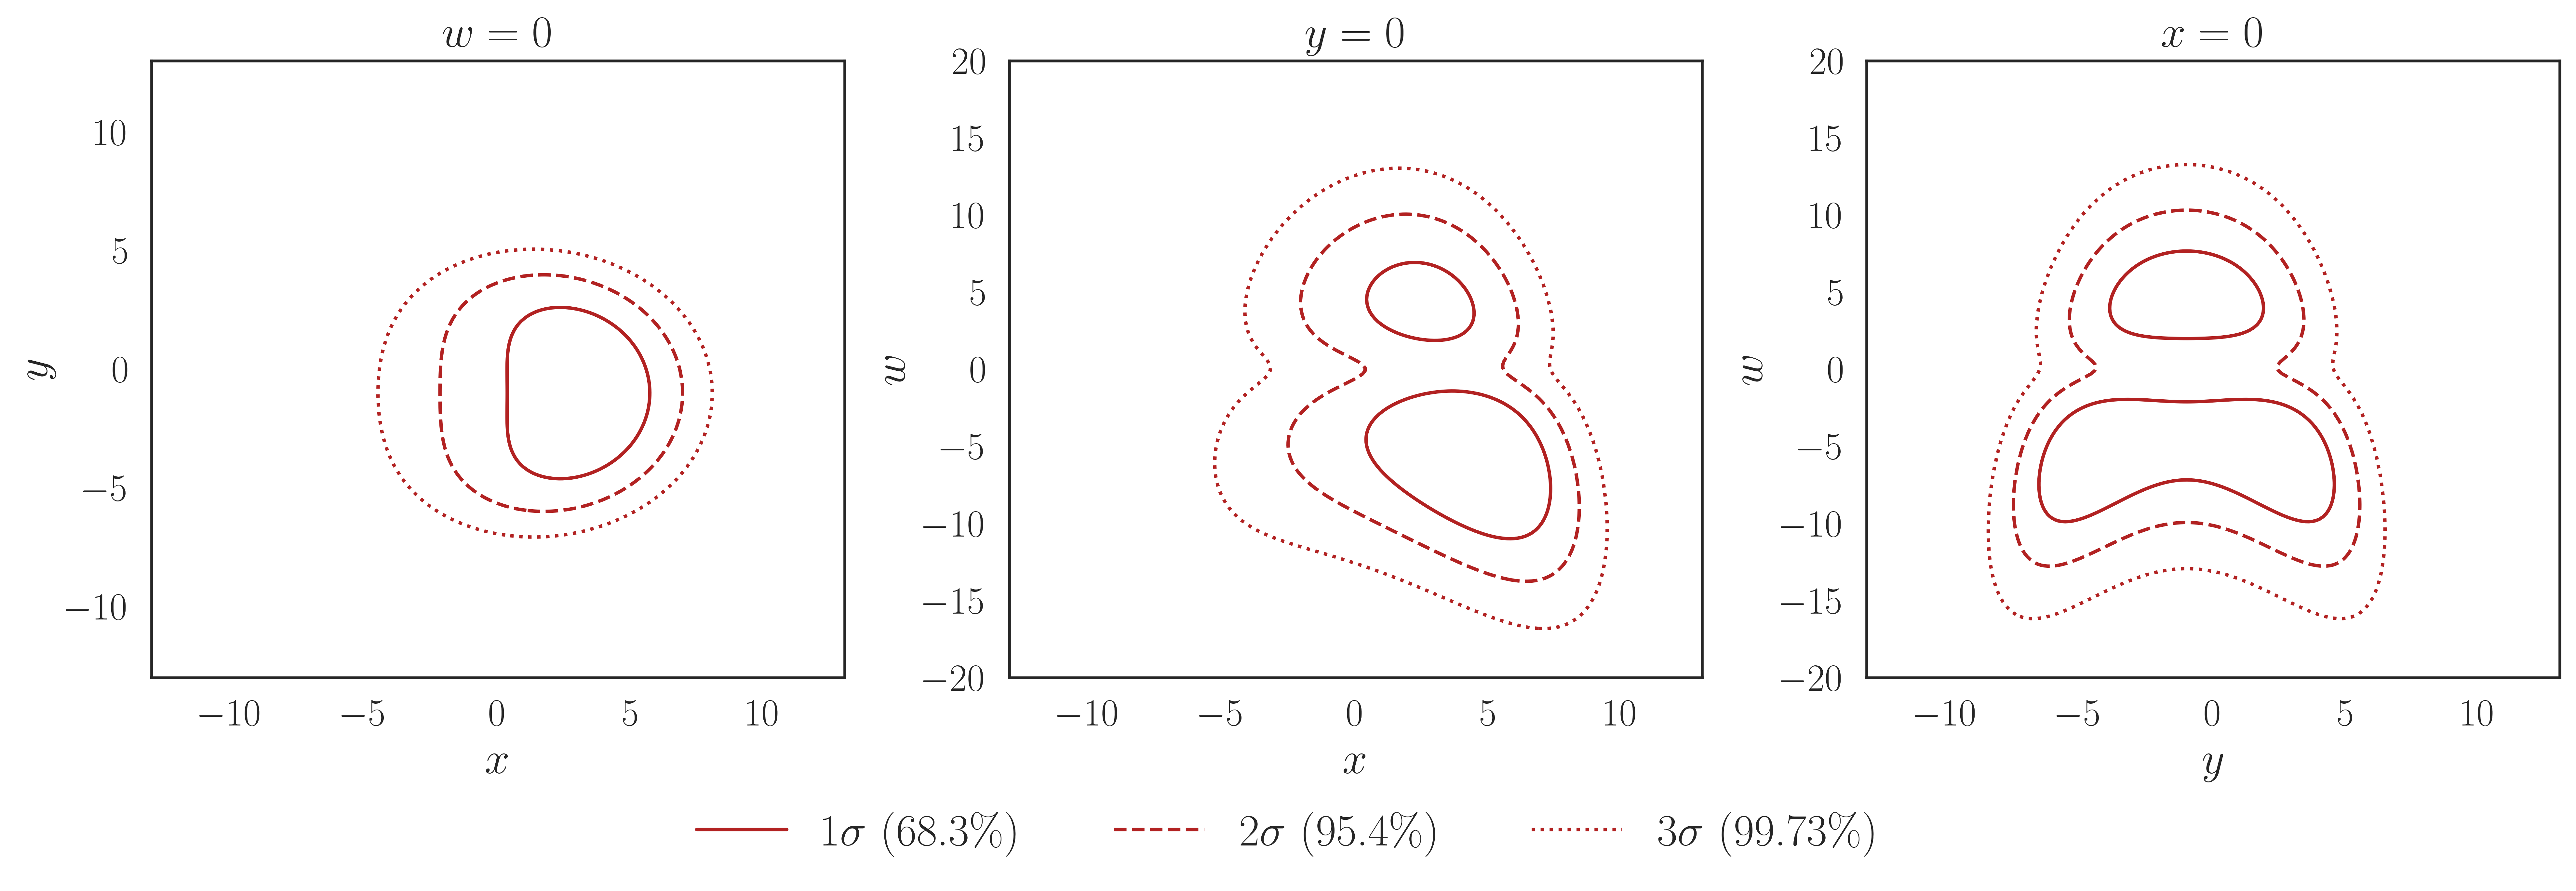

In [139]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=500)

planos = [
    (X_xy, Y_xy, P_xy_a, levels_xy_a, r'$x$', r'$y$', r'$w=0$'),
    (X_xw, W_xw, P_xw_a, levels_xw_a, r'$x$', r'$w$', r'$y=0$'),
    (Y_yw, W_yw, P_yw_a, levels_yw_a, r'$y$', r'$w$', r'$x=0$')
]

for ax, (X, Y, P, levels, xlabel, ylabel, titulo) in zip(axes, planos):
    ax.contour(X, Y, P, levels=levels, colors='firebrick', linestyles=[':', '--', '-'], linewidths=1.5)
    ax.set_xlabel(xlabel, fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_title(titulo, fontsize=20)
    ax.tick_params(axis='both', labelsize=17)

legenda = [
    Line2D([0], [0], color='firebrick', ls='-', lw=1.5,
           label=r'$1\sigma$ (68.3\%)'),
    Line2D([0], [0], color='firebrick', ls='--', lw=1.5,
           label=r'$2\sigma$ (95.4\%)'),
    Line2D([0], [0], color='firebrick', ls=':', lw=1.5,
           label=r'$3\sigma$ (99.73\%)')
]

fig.legend(handles=legenda, loc='lower center', ncol=3, frameon=False, fontsize=20, bbox_to_anchor=(0.5, -0.12))

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)

plt.show()

### 4b. Fixar o terceiro parâmetro no valor máximo

In [140]:
X, Y, W = np.meshgrid(x4, y4, w4, indexing='ij')
P = posterior_4(X, Y, W)
idx = np.unravel_index(np.argmax(P), P.shape)

x_max = x4[idx[0]]
y_max = y4[idx[1]]
w_max = w4[idx[2]]

print(f"x_max = {x_max:.5f}")
print(f"y_max = {y_max:.5f}")
print(f"w_max = {w_max:.5f}")

x_max = 4.63819
y_max = -0.97990
w_max = -5.52764


In [141]:
P_xy_b = normalization(posterior_4(X_xy, Y_xy, w_max), x4, y4)
P_xw_b = normalization(posterior_4(X_xw, y_max, W_xw), x4, w4)
P_yw_b = normalization(posterior_4(x_max, Y_yw, W_yw), y4, w4)

levels_xy_b = credible_levels(P_xy_b, x4, y4)
levels_xw_b = credible_levels(P_xw_b, x4, w4)
levels_yw_b = credible_levels(P_yw_b, y4, w4)


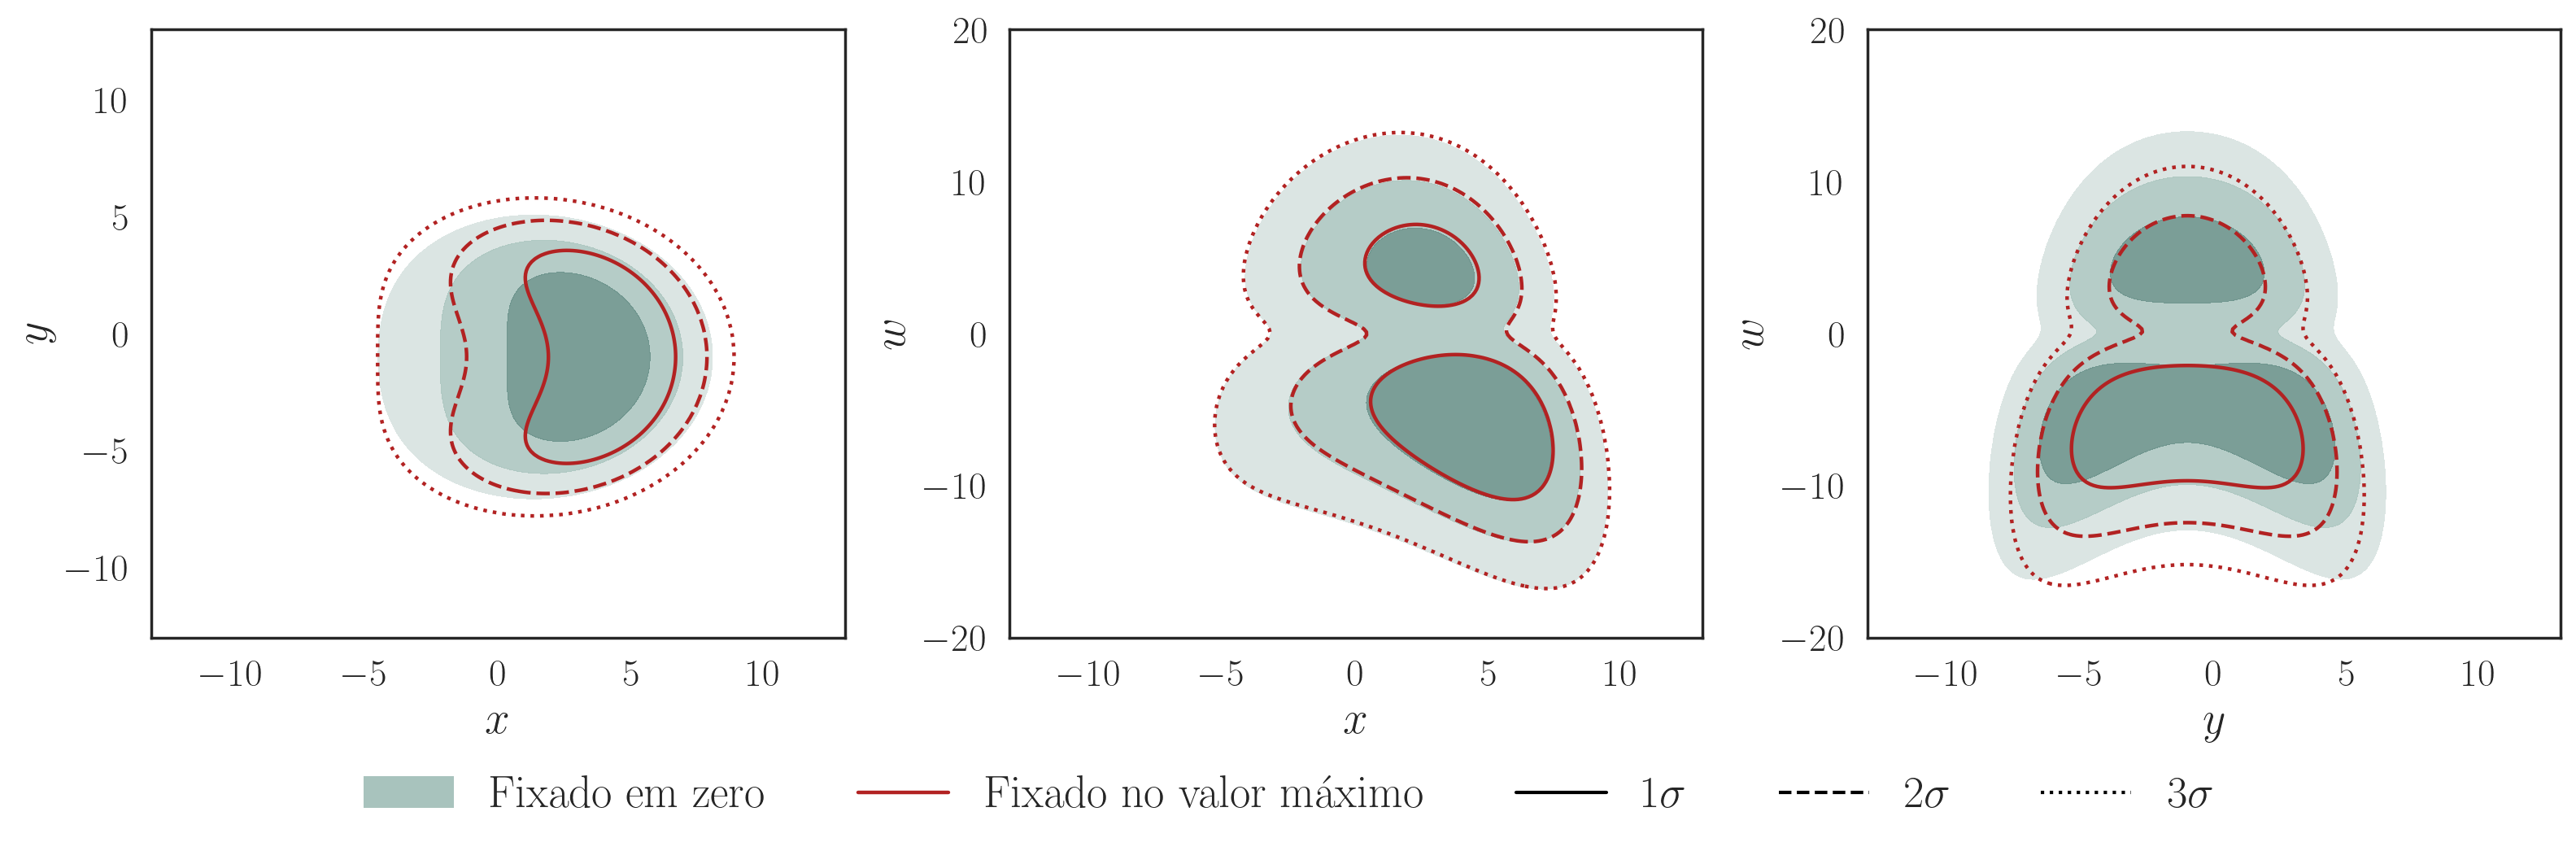

In [142]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=200)

planos = [(X_xy, Y_xy, P_xy_a, P_xy_b, levels_xy_a, levels_xy_b, r'$x$', r'$y$'), (X_xw, W_xw, P_xw_a, P_xw_b, levels_xw_a, levels_xw_b, r'$x$', r'$w$'), (Y_yw, W_yw, P_yw_a, P_yw_b, levels_yw_a, levels_yw_b, r'$y$', r'$w$')]

for ax, (X, Y, P_a, P_b, levels_a, levels_b, xlabel, ylabel) in zip(axes, planos):
    ax.contourf(X, Y, P_a, levels=[*levels_a, np.inf],  colors=['#D5E1DE', '#A8C3BD', '#648D85'], alpha=0.85)
    ax.contour(X, Y, P_b, levels=levels_b, colors='firebrick', linestyles=[':', '--', '-'], linewidths=1.6)

    ax.set_xlabel(xlabel, fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.tick_params(axis='both', labelsize=17)

legend = [Patch(facecolor='#A8C3BD', edgecolor='none',
          label='Fixado em zero'),

    Line2D([0], [0], color='firebrick', lw=1.6,
           label='Fixado no valor máximo'),

    Line2D([0], [0], color='black', ls='-', lw=1.5,
           label=r'$1\sigma$'),

    Line2D([0], [0], color='black', ls='--', lw=1.5,
           label=r'$2\sigma$'),

    Line2D([0], [0], color='black', ls=':', lw=1.5,
           label=r'$3\sigma$')]

fig.legend(handles=legend, loc='lower center', ncol=5, frameon=False, fontsize=20, bbox_to_anchor=(0.5, -0.07))

plt.tight_layout()
plt.subplots_adjust(bottom=0.20)

plt.show()

### 4c. Marginalização

In [143]:
X, Y, W = np.meshgrid(x4, y4, w4, indexing='ij')

P = posterior_4(X, Y, W)

P_xy_c = np.trapezoid(P, w4, axis=2)
P_xw_c = np.trapezoid(P, y4, axis=1)
P_yw_c = np.trapezoid(P, x4, axis=0)

P_xy_c = normalization(P_xy_c, x4, y4)
P_xw_c = normalization(P_xw_c, x4, w4)
P_yw_c = normalization(P_yw_c, y4, w4)

levels_xy_c = credible_levels(P_xy_c, x4, y4)
levels_xw_c = credible_levels(P_xw_c, x4, w4)
levels_yw_c = credible_levels(P_yw_c, y4, w4)

P_xy_c_plot = P_xy_c.T
P_xw_c_plot = P_xw_c.T
P_yw_c_plot = P_yw_c.T

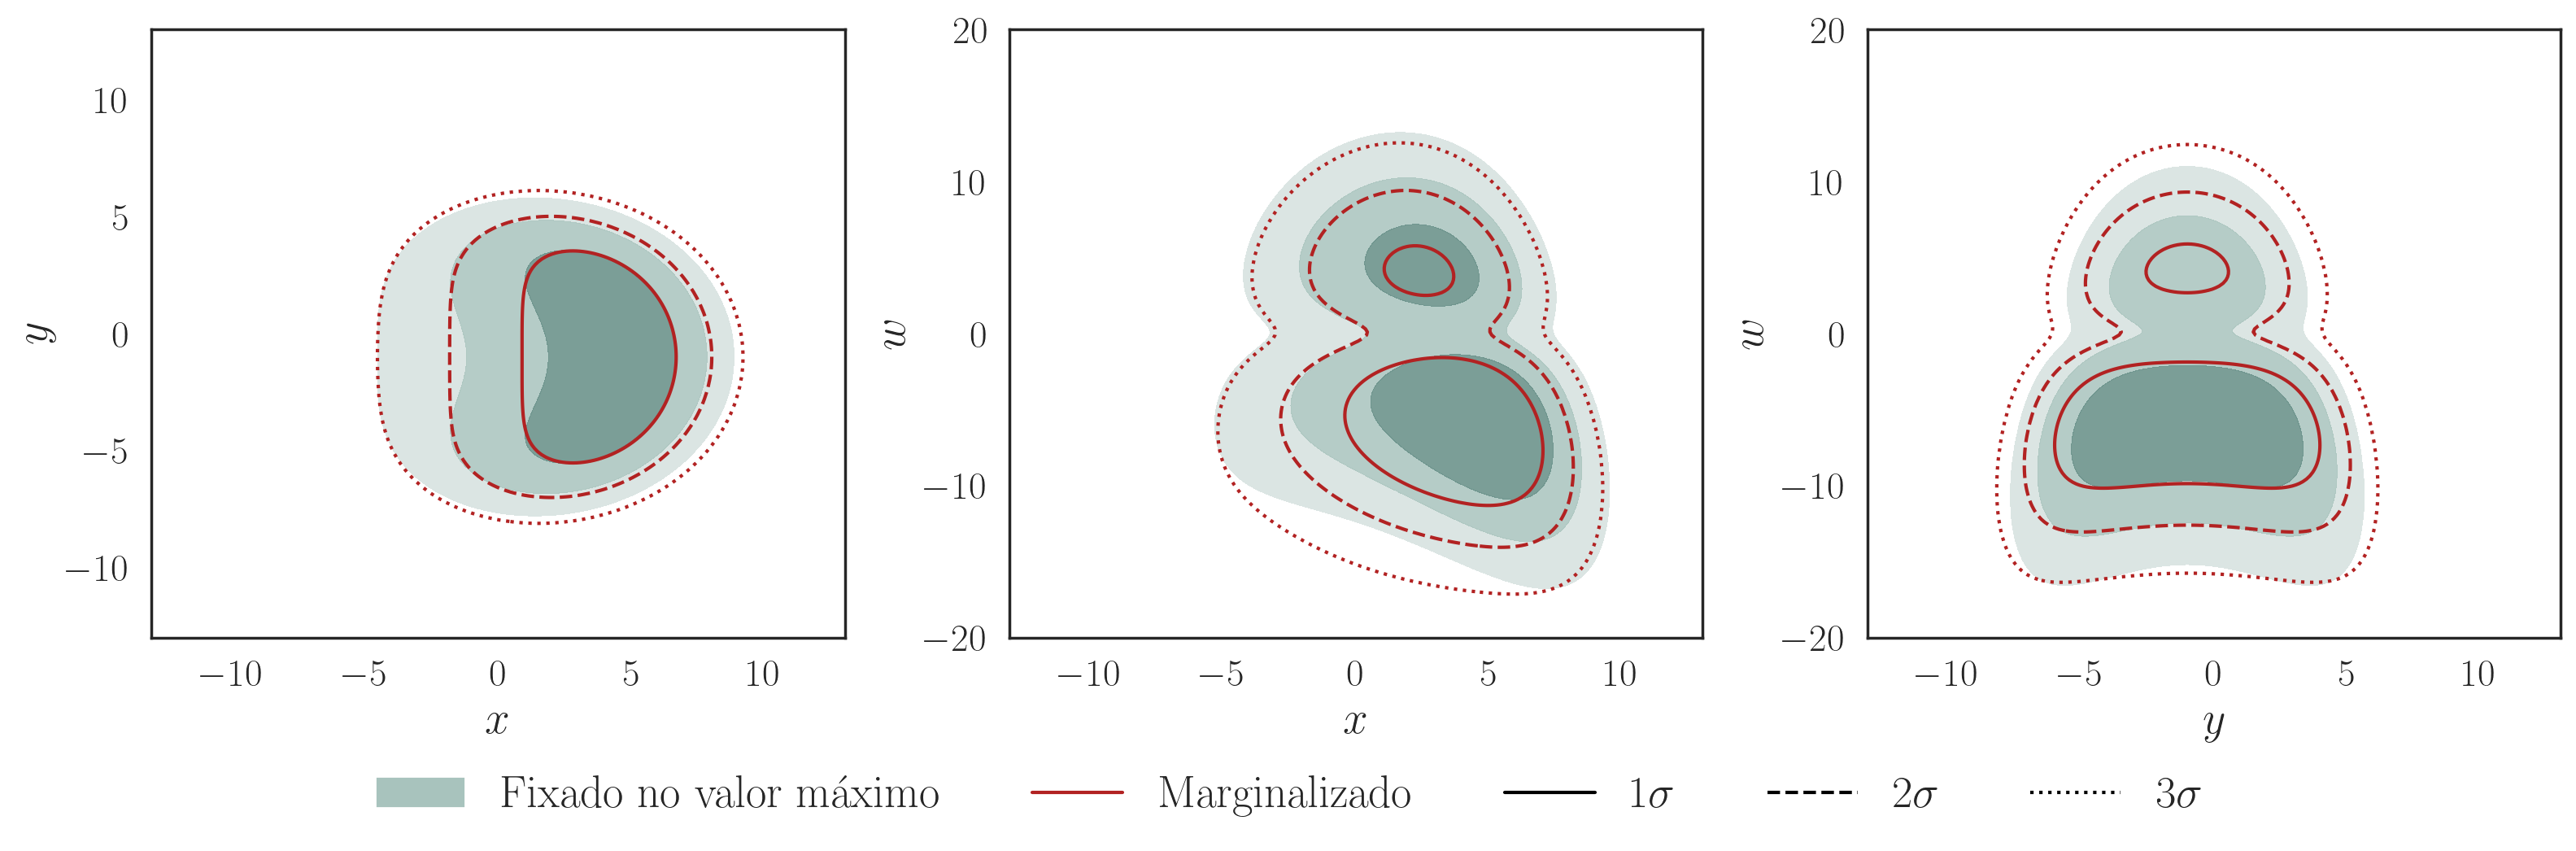

In [144]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=200)

planos = [(X_xy, Y_xy, P_xy_b, P_xy_c_plot, levels_xy_b, levels_xy_c, r'$x$', r'$y$'), (X_xw, W_xw, P_xw_b, P_xw_c_plot, levels_xw_b, levels_xw_c, r'$x$', r'$w$'), (Y_yw, W_yw, P_yw_b, P_yw_c_plot, levels_yw_b, levels_yw_c, r'$y$', r'$w$')]

for ax, (X, Y, P_b, P_c, levels_b, levels_c, xlabel, ylabel) in zip(axes, planos):

    ax.contourf(X, Y, P_b, levels=[*levels_b, np.inf], colors=['#D5E1DE', '#A8C3BD', '#648D85'], alpha=0.85)

    ax.contour(X, Y, P_c, levels=levels_c, colors='firebrick', linestyles=[':', '--', '-'], linewidths=1.5)

    ax.set_xlabel(xlabel, fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.tick_params(axis='both', labelsize=17)

legenda = [Patch(facecolor='#A8C3BD',
          label='Fixado no valor máximo'),

    Line2D([0], [0], color='firebrick', lw=1.5,
           label='Marginalizado'),

    Line2D([0], [0], color='black', ls='-', lw=1.5,
           label=r'$1\sigma$'),

    Line2D([0], [0], color='black', ls='--', lw=1.5,
           label=r'$2\sigma$'),

    Line2D([0], [0], color='black', ls=':', lw=1.5,
           label=r'$3\sigma$')]

fig.legend(handles=legenda, loc='lower center', ncol=5, frameon=False, fontsize=20, bbox_to_anchor=(0.5, -0.07))

plt.tight_layout()
plt.subplots_adjust(bottom=0.20)

plt.show()

## Questão 5: Matriz de Fisher

### 5a. Construindo a Matriz de Fisher e fixando $w=0$

In [146]:
def fisher_4(x, y, w):
    Q = y + 0.5*y**2 + 0.3*x**2 + w

    F_xx = 1/9 + (0.36*x**2 + 0.6*Q)/36
    F_yy = ((1 + y)**2 + Q)/36
    F_ww = (1/36 + 1/16 - 4*(3 - 2*w**2)/(2*w**2 + 3)**2)
    
    F_xy = 0.6*x*(1 + y)/36
    F_xw = 0.6*x/36
    F_yw = (1 + y)/36

    return np.array([[F_xx, F_xy, F_xw], [F_xy, F_yy, F_yw], [F_xw, F_yw, F_ww]])

F_3D = fisher_4(x_max, y_max, w_max)
C_3D = np.linalg.inv(F_3D)

print("Fisher matrix (3D):")
print(F_3D)

Fisher matrix (3D):
[[0.33334607 0.00155383 0.07730318]
 [0.00155383 0.0118559  0.00055835]
 [0.07730318 0.00055835 0.1468316 ]]


In [148]:
idx = np.unravel_index(np.argmax(P_xy_a), P_xy_a.shape)

y_fixed = y4[idx[0]]
x_fixed = x4[idx[1]]

F_fixed = fisher_4(x_fixed, y_fixed, 0)[:2, :2]
C_fixed = np.linalg.inv(F_fixed)

print(f"x_max (w=0) = {x_fixed:.5f}")
print(f"y_max (w=0) = {y_fixed:.5f}")

print("\nFisher matrix (w=0):")
print(F_fixed)

x_max (w=0) = 3.46231
y_max (w=0) = -0.97990

Fisher matrix (w=0):
[[0.28259516 0.0011599 ]
 [0.0011599  0.08602462]]


In [149]:
C_marg = C_3D[:2, :2]
F_marg = np.linalg.inv(C_marg)

print("Marginalized Fisher matrix:")
print(F_marg)

Marginalized Fisher matrix:
[[0.29264787 0.00125988]
 [0.00125988 0.01185378]]


### 5b. Comparação de contornos

Delta chi2: [ 2.29770701  6.15822776 11.82900701]


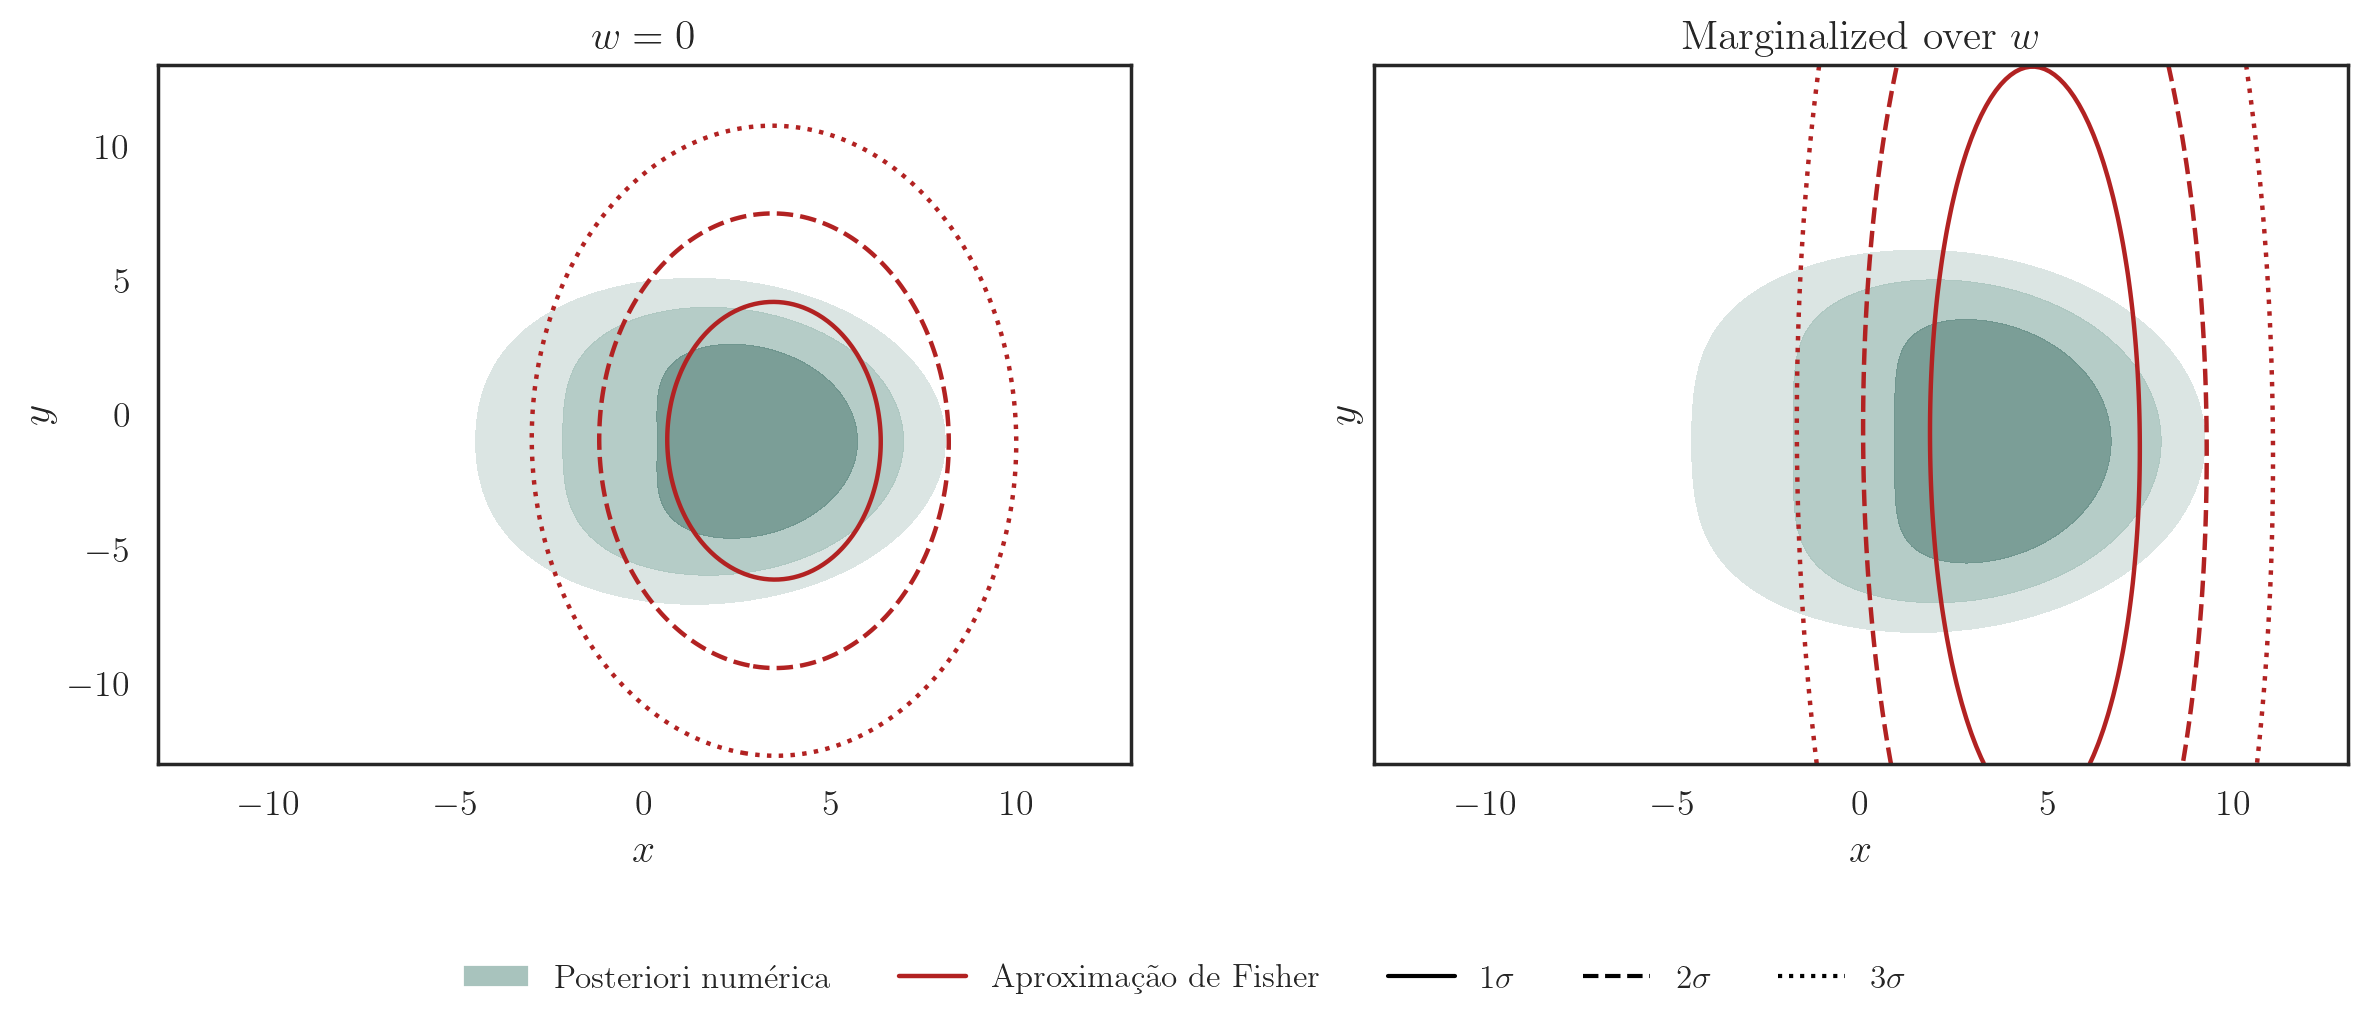

In [150]:
probabilities = np.array([0.683, 0.954, 0.9973])
delta_chi2 = -2 * np.log(1 - probabilities)

print("Delta chi2:", delta_chi2)

def fisher_chi2(X, Y, F, x0, y0):
    dx = X - x0
    dy = Y - y0
    return F[0, 0] * dx**2 + 2 * F[0, 1] * dx * dy + F[1, 1] * dy**2


chi2_fixed = fisher_chi2(X_xy, Y_xy, F_fixed, x_fixed, y_fixed)
chi2_marg = fisher_chi2(X_xy, Y_xy, F_marg, x_max, y_max)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=200, sharex=True, sharey=True)

cases = [(P_xy_a, levels_xy_a, chi2_fixed, r'$w=0$'), (P_xy_c_plot, levels_xy_c, chi2_marg, 'Marginalized over $w$')]

for ax, (P, levels, chi2, title) in zip(axes, cases):
    ax.contourf(X_xy, Y_xy, P, levels=[*levels, np.inf], colors= ['#D5E1DE', '#A8C3BD', '#648D85'], alpha=0.85)

    ax.contour(X_xy, Y_xy, chi2, levels=delta_chi2, colors='firebrick', linestyles=['-', '--', ':'], linewidths=1.6)

    ax.set_xlabel(r'$x$', fontsize=15)
    ax.set_ylabel(r'$y$', fontsize=15)
    ax.set_title(title, fontsize=15)
    ax.tick_params(axis='both', labelsize=13)

legend = [Patch(facecolor='#A8C3BD', label='Posteriori numérica'), 
          Line2D([0], [0], color='firebrick', lw=1.6, label='Aproximação de Fisher'), 
          Line2D([0], [0], color='black', ls='-', lw=1.5, label=r'$1\sigma$'), 
          Line2D([0], [0], color='black', ls='--', lw=1.5, label=r'$2\sigma$'), 
          Line2D([0], [0], color='black', ls=':', lw=1.5, label=r'$3\sigma$')]

fig.legend(handles=legend, loc='lower center', ncol=5, frameon=False, fontsize=12, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.subplots_adjust(bottom=0.22, wspace=0.25)

plt.show()